# RL Group Project: Starter Notebook
## Clinical Treatment Optimisation: Sepsis ICU Management

**Master in Data Science & Advanced Analytics — Reinforcement Learning Course**

This project is structured in two stages of increasing complexity.

- In **Configuration A**, you will work with a tabular Sepsis MDP, where the state and action spaces are small enough to apply classical RL methods directly. 

- In **Configuration B**, you will move to a continuous-observation ICU environment that is clinically grounded and significantly more challenging. 

Three realistic failure modes are present in Configuration B, each reflecting a real scenario encountered in clinical AI deployments. The first is episodic observation noise, where monitoring equipment occasionally malfunctions. The second is episodic missing observations, representing situations where lab results are simply unavailable for an entire episode. The third is acute clinical events, which are sudden and irreversible patient deteriorations that occur independently of any treatment given.


---
### Group Members
Fill in before submitting:

Name of the Group: Group AC

```
Student 1: Duarte Neves 20221880 
Student 2: Margarida Ourives 20221809
Student 3: Ricardo Trindade 20222039
Student 4: Rodrigo Amaral 20221943
```


## 0. Setup & Imports


In [42]:
# Install dependencies (run once)
# !pip install icu-sepsis numpy pandas matplotlib seaborn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import warnings
import os
import sys
import time

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

os.makedirs('plots', exist_ok=True)
PLOTS_DIR = 'plots'

SEED = 42
np.random.seed(SEED)

#  Import constants and env factory from env_setup.py 
from envs.env_setup import (
    ENV_ID, N_STATES, N_ACTIONS, STATE_SURVIVED, STATE_DIED,
    GAMMA, INTENSITY, SOFA_BIAS, LAM,
    make_sepsis_env,
)

print(f'ICU-Sepsis-v2 | States: {N_STATES} | Actions: {N_ACTIONS}')
print(f'Terminal states: {STATE_SURVIVED} (survived, r=+1)  {STATE_DIED} (died, r=0)')
print('Setup complete!')


ICU-Sepsis-v2 | States: 716 | Actions: 25
Terminal states: 714 (survived, r=+1)  713 (died, r=0)
Setup complete!


In [43]:
# Configuration already loaded from env_setup.py
# env_setup.py defines: SOFA_BIAS=5.0, LAM=0.02, INTENSITY, make_sepsis_env()
print(f'Required config: sofa_bias={SOFA_BIAS}, lam={LAM}')

Required config: sofa_bias=5.0, lam=0.02


In [44]:
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
 
os.makedirs("plots", exist_ok=True)
PLOTS_DIR = "plots"
 

---
## 1. Explore the Environment

Before writing any algorithm, take time to understand the MDP you are working with. The insights you gain here should inform your report's Methodology section.

`ICU-Sepsis-v2` is a benchmark MDP constructed from real MIMIC-III patient data. Each episode represents the trajectory of one ICU patient. The agent observes a discrete integer state (ranging from 0 to 715) and must select one of 25 treatment actions corresponding to combinations of vasopressor and IV fluid dose levels. The reward signal is sparse: **+1 at survival, 0 at death, and 0 for all intermediate steps**, with a discount factor γ = 1.


In [45]:
#  Instantiate and inspect the raw environment 
env = make_sepsis_env()
obs, info = env.reset(seed=SEED)

print(f'Observation space : {env.observation_space} discrete integer state')
print(f'Action space      : {env.action_space}')
print(f'Initial state     : {obs}')
print()

#  Extract the full MDP model 
raw = env.unwrapped
P = raw._tx_mat    # shape (716, 25, 716) — P[s,a,s'] = P(s'|s,a)
R_sasp = raw._r_mat                    # (716, 25, 716) — R[s, a, s']
R = (P * R_sasp).sum(axis=2)          # (716, 25)      — E[r | s, a]

print(f'Transition matrix P : {P.shape}  (S × A × S\')')
print(f'Reward matrix R     : {R.shape}  (S × A)')
print(f'Reward range        : [{R.min():.3f}, {R.max():.3f}]')
print()


make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
Observation space : Discrete(716) discrete integer state
Action space      : Discrete(25)
Initial state     : 559

Transition matrix P : (716, 25, 716)  (S × A × S')
Reward matrix R     : (716, 25)  (S × A)
Reward range        : [-0.020, 0.708]



In [56]:
#  Random baseline: establish the performance floor 
def run_random_baseline(n_episodes=1000, seed=SEED):
    np.random.seed(seed)
    env_eval = make_sepsis_env()
    returns, lengths = [], []
    for _ in range(n_episodes):
        obs, _ = env_eval.reset(seed=np.random.randint(100_000))
        total_r, steps, done = 0.0, 0, False
        while not done:
            obs, r, te, tr, _ = env_eval.step(env_eval.action_space.sample())
            total_r += r; steps += 1; done = te or tr
        returns.append(total_r)
        lengths.append(steps)
    env_eval.close()
    return np.array(returns), np.array(lengths)


rand_returns, rand_lengths = run_random_baseline()
survival_rate = float(np.mean(rand_returns > 0)) * 100

print(f'Random agent ({len(rand_returns)} episodes):')
print(f'  Mean return    : {np.mean(rand_returns):.4f}')
print(f'  Survival rate  : {survival_rate:.1f}%')
print(f'  Mean ep length : {np.mean(rand_lengths):.1f} steps')
print()
print('All Config A algorithms must beat the random baseline.')


make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
Random agent (1000 episodes):
  Mean return    : 0.5694
  Survival rate  : 67.0%
  Mean ep length : 10.1 steps

All Config A algorithms must beat the random baseline.


make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


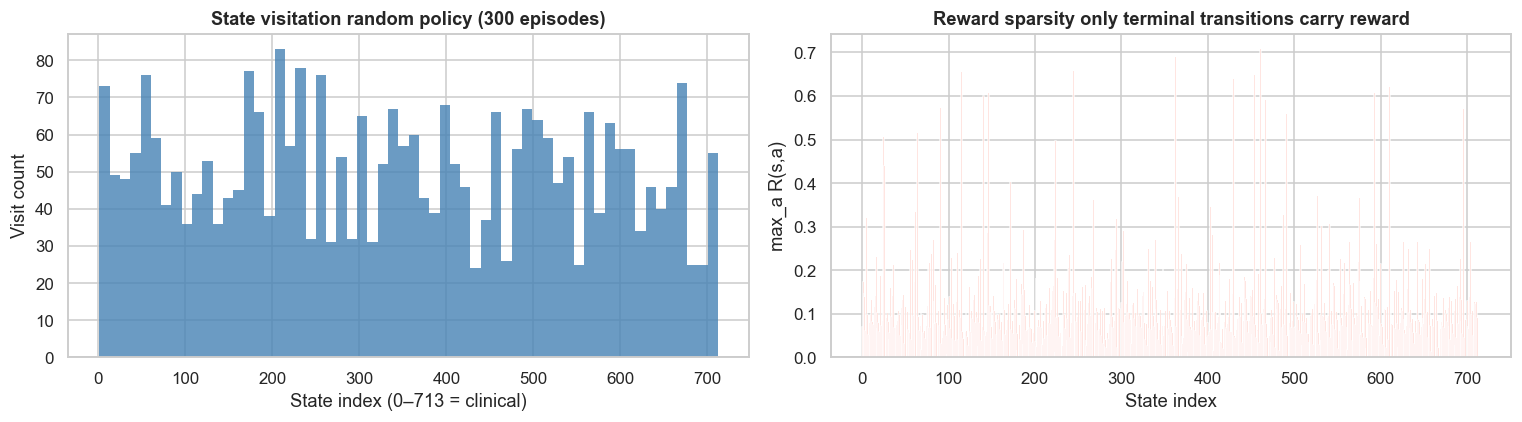

In [47]:
#  Visualise state visitation and reward structure 
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# State visitation under random policy
np.random.seed(SEED)
env_vis = make_sepsis_env()
visited = []
for _ in range(300):
    obs, _ = env_vis.reset(seed=np.random.randint(100_000))
    done = False
    while not done:
        visited.append(int(obs))
        obs, _, te, tr, _ = env_vis.step(env_vis.action_space.sample())
        done = te or tr
env_vis.close()
clinical = [s for s in visited if s not in (STATE_SURVIVED, STATE_DIED)]

axes[0].hist(clinical, bins=60, color='steelblue', edgecolor='none', alpha=0.8)
axes[0].set_xlabel('State index (0–713 = clinical)')
axes[0].set_ylabel('Visit count')
axes[0].set_title('State visitation random policy (300 episodes)', fontweight='bold')

# Max achievable reward per state (only survival-adjacent states have r > 0)
axes[1].bar(range(N_STATES), R.max(axis=1), color='tomato', width=1.0, alpha=0.8)
axes[1].set_xlabel('State index')
axes[1].set_ylabel('max_a R(s,a)')
axes[1].set_title('Reward sparsity only terminal transitions carry reward',
                  fontweight='bold')

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/configA_env_exploration.png', bbox_inches='tight')
plt.show()


---
# Config B: RL on the Clinical ICU-Sepsis Environment

In Config A, patient state was represented as a discrete integer produced by discretising a set of clinical measurements into a small number of categories. **Config B uses the full ICU-Sepsis environment**, also built from MIMIC-III data, but with two fundamental changes that make the problem substantially harder.

**Change 1 — Continuous observations.**
The agent now receives a **47-dimensional continuous feature vector** instead of a single discrete index. This vector contains the actual normalised physiological measurements used in the original Komorowski et al. (2018) AI Clinician study, including SOFA score, heart rate, lactate, blood pressure, creatinine, and 42 other clinical variables.

With continuous observations, a tabular Q-table is no longer feasible: it would require one entry per unique float vector, making it effectively infinite. 

**Change 2 — Clinical reality wrappers.**
Config B injects three orthogonal failure modes that reflect challenges faced by real clinical AI deployments.

The first wrapper, `EpisodicNoisyObsEnv`, models episodic monitor malfunction. When active, the observations received by the agent are corrupted by noise for the entire episode, testing robustness to measurement error.

The second wrapper, `EpisodicMissingObsEnv`, models situations where lab results are unavailable for a full episode. This tests how well the agent handles partial observability.

The third wrapper, `AcuteEventEnv`, introduces rare, sudden patient deterioration events such as cardiac arrest or acute organ failure. These occur independently of any treatment decision and represent irreducible stochasticity in the environment.


Key environment properties for Config B:
- **Actions**: 25 total (5 vasopressor levels × 5 IV fluid dose levels)
- **Reward**: +1.0 at survival, 0.0 at death, plus a small treatment intensity penalty (lam = 0.02)
- **Observation**: `Box(47,)`, a normalised physiological feature vector, potentially noisy or incomplete

## Setup: Clinical ICU-Sepsis Environment


In [48]:
#  Import Clinical Reality Wrappers from wrappers.py 

from envs.wrappers import (
    EpisodicNoisyObsEnv,
    EpisodicMissingObsEnv,
    AcuteEventEnv,
    make_clinical_env,
)

print('Clinical reality wrappers imported from wrappers.py:')
print('  EpisodicNoisyObsEnv   : episodic monitor malfunction')
print('  EpisodicMissingObsEnv : episodic missing lab values')
print('  AcuteEventEnv         : rare sudden patient death')
print()
print('Required Config B env: make_clinical_env() with default parameters')


Clinical reality wrappers imported from wrappers.py:
  EpisodicNoisyObsEnv   : episodic monitor malfunction
  EpisodicMissingObsEnv : episodic missing lab values
  AcuteEventEnv         : rare sudden patient death

Required Config B env: make_clinical_env() with default parameters


In [49]:

try:
    env_clinical = make_clinical_env()
    obs, info = env_clinical.reset(seed=SEED)

    print('Clinical environment loaded successfully!')
    print(f'Observation space : {env_clinical.observation_space}')
    print(f'Action space      : {env_clinical.action_space}')
    print(f'Info keys         : {list(info.keys())}')
    print()

    # Random baseline on clinical env (1000 episodes)
    np.random.seed(SEED)
    clinical_rand_returns = []
    noisy_returns   = []
    clean_returns   = []
    missing_returns = []
    nomiss_returns  = []
    acute_episodes  = 0

    env_eval = make_clinical_env()
    for ep in range(1000):
        obs, info = env_eval.reset(seed=np.random.randint(100_000))
        total_r, done = 0.0, False
        ep_noisy   = info.get('noisy_episode', False)
        ep_missing = info.get('missing_features') is not None
        ep_acute   = False

        while not done:
            obs, r, te, tr, info = env_eval.step(env_eval.action_space.sample())
            total_r += r
            done = te or tr
            if info.get('acute_event', False):
                ep_acute = True

        clinical_rand_returns.append(total_r)
        if ep_noisy:   noisy_returns.append(total_r)
        else:          clean_returns.append(total_r)
        if ep_missing: missing_returns.append(total_r)
        else:          nomiss_returns.append(total_r)
        if ep_acute:   acute_episodes += 1

    env_eval.close()
    env_clinical.close()

    print()
    print('=== Random Baseline: Clinical Environment (1000 episodes) ===')
    print(f'Overall mean return   : {np.mean(clinical_rand_returns):.4f}')
    print(f'Overall survival rate : {np.mean(np.array(clinical_rand_returns) > 0)*100:.1f}%')
    print()

    # Store for later comparison
    clinical_rand_mean = float(np.mean(clinical_rand_returns))

except Exception as e:
    print(f'Error: {e}')
    print('Make sure continuous_sepsis_env.py is in the project root and dependencies are installed.')
    clinical_rand_mean = 0.78


make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
Clinical environment loaded successfully!
Observation space : Box(-inf, inf, (47,), float32)
Action space      : Discrete(25)
Info keys         : ['admissible_actions', 'state_vector', 'sofa_score', 'noisy_episode', 'missing_features']

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02

=== Random Baseline: Clinical Environment (1000 episodes) ===
Overall mean return   : 0.5610
Overall survival rate : 65.3%



In [50]:
test_env = make_clinical_env()
e = test_env
while hasattr(e, 'env'):
    print(type(e).__name__)
    e = e.env
print(type(e).__name__)
test_env.close()

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
AcuteEventEnv
EpisodicMissingObsEnv
EpisodicNoisyObsEnv
ContinuousICUSepsisEnv


In [51]:
! pip install 'stable-baselines3[extra]'

  Using cached numpy-1.26.4-cp312-cp312-macosx_10_9_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-macosx_10_9_x86_64.whl (20.3 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3
^C


## DQN

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import DQN, PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.results_plotter import load_results, ts2xy
import warnings
warnings.filterwarnings("ignore")
 
SEED = 42
 
 
# Callback to track episode returns during training
 
class ReturnTracker(BaseCallback):
    """
    Logs episode returns and survival rate during training.
    Access via: callback.episode_returns, callback.survival_rates
    """
    def __init__(self, verbose=0):
        super().__init__(verbose)
        self.episode_returns  = []
        self.survival_rates   = []
        self._current_returns = {}   # env_idx → cumulative reward
 
    def _on_step(self) -> bool:
        # SB3 stores episode info in self.locals["infos"]
        for i, done in enumerate(self.locals["dones"]):
            # accumulate reward
            reward = self.locals["rewards"][i]
            self._current_returns[i] = self._current_returns.get(i, 0.0) + reward
            if done:
                ep_return = self._current_returns.pop(i, 0.0)
                self.episode_returns.append(ep_return)
                self.survival_rates.append(1.0 if ep_return > 0 else 0.0)
        return True
 
 
# Wrap the clinical environment for SB3
 
def make_monitored_env():
    """Wraps make_clinical_env() in SB3's Monitor for logging."""
    env = make_clinical_env()         # your existing function
    env = Monitor(env)
    return env

In [ ]:
# Instantiate
dqn_model = DQN(
    policy              = "MlpPolicy",
    env                 = make_monitored_env(),
    learning_rate       = 1e-3,
    buffer_size         = 50_000,        # replay buffer size
    learning_starts     = 1_000,         # steps before first gradient update
    batch_size          = 64,
    tau                 = 1.0,           # hard target update (tau=1 = hard copy)
    gamma               = 0.99,
    train_freq          = 1,             # update every step
    target_update_interval = 500,        # steps between target net updates
    exploration_fraction   = 0.4,        # fraction of training for ε decay
    exploration_final_eps  = 0.05,
    policy_kwargs       = dict(net_arch=[128, 128]),
    verbose             = 0,
    seed                = SEED,
)
 
dqn_callback = ReturnTracker()
 
print("Training DQN...")
dqn_model.learn(
    total_timesteps = 600_000,
    callback        = dqn_callback,
    progress_bar    = True,
)
print(f"DQN training done. Episodes: {len(dqn_callback.episode_returns)}")
print(f"  Last 100 ep mean return  : {np.mean(dqn_callback.episode_returns[-100:]):.4f}")
print(f"  Last 100 ep survival rate: {np.mean(dqn_callback.survival_rates[-100:])*100:.1f}%")

Output()

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
Training DQN...


DQN training done. Episodes: 63840
  Last 100 ep mean return  : 0.5218
  Last 100 ep survival rate: 60.0%


## PPO

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 6 — Train PPO
# ─────────────────────────────────────────────────────────────────────────────
 
# PPO works best with a vectorised env (parallel rollout collection)
vec_env = make_vec_env(make_clinical_env, n_envs=4, seed=SEED)
 
ppo_model = PPO(
    policy         = "MlpPolicy",
    env            = vec_env,
    learning_rate  = 3e-4,
    n_steps        = 512,          # steps per env per rollout → batch = n_steps * n_envs
    batch_size     = 64,
    n_epochs       = 10,           # gradient epochs per rollout
    gamma          = 0.99,
    gae_lambda     = 0.95,         # GAE lambda for advantage estimation
    clip_range     = 0.2,          # PPO clipping parameter
    ent_coef       = 0.01,         # entropy bonus (encourages exploration)
    policy_kwargs  = dict(net_arch=[dict(pi=[128, 128], vf=[128, 128])]),
    verbose        = 0,
    seed           = SEED,
)
 
ppo_callback = ReturnTracker()
 
print("Training PPO...")
ppo_model.learn(
    total_timesteps = 600_000,
    callback        = ppo_callback,
    progress_bar    = True,
)
print(f"PPO training done. Episodes: {len(ppo_callback.episode_returns)}")
print(f"  Last 100 ep mean return  : {np.mean(ppo_callback.episode_returns[-100:]):.4f}")
print(f"  Last 100 ep survival rate: {np.mean(ppo_callback.survival_rates[-100:])*100:.1f}%")

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Output()

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
Training PPO...


PPO training done. Episodes: 66951
  Last 100 ep mean return  : 0.6436
  Last 100 ep survival rate: 70.0%


In [ ]:
# Evaluation function (with wrapper breakdown)
 
def evaluate_sb3(model, n_episodes=1000, seed=0, label="Agent"):
    """
    Greedy evaluation of an SB3 model.
    Returns a dict with overall and per-wrapper results.
    """
    np.random.seed(seed)
    env = make_clinical_env()
 
    returns         = []
    noisy_ret       = []
    clean_ret       = []
    missing_ret     = []
    nomissing_ret   = []
    acute_episodes  = 0
 
    for _ in range(n_episodes):
        obs, info  = env.reset(seed=np.random.randint(100_000))
        total_r    = 0.0
        done       = False
        ep_noisy   = info.get("noisy_episode", False)
        ep_missing = info.get("missing_features") is not None
        ep_acute   = False
 
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            obs, r, te, tr, info = env.step(int(action))
            total_r += r
            done = te or tr
            if info.get("acute_event", False):
                ep_acute = True
 
        returns.append(total_r)
        (noisy_ret   if ep_noisy   else clean_ret).append(total_r)
        (missing_ret if ep_missing else nomissing_ret).append(total_r)
        if ep_acute:
            acute_episodes += 1
 
    env.close()
    arr = np.array(returns)
 
    print("=" * 55)
    print(f"  {label} — Greedy Evaluation ({n_episodes} episodes)")
    print("=" * 55)
    print(f"  Mean return        : {arr.mean():.4f}")
    print(f"  Survival rate      : {(arr > 0).mean()*100:.1f}%")
    print(f"  Std return         : {arr.std():.4f}")
    print("-" * 55)
    if noisy_ret:
        print(f"  Noisy episodes     : {np.mean(noisy_ret):.4f}  (n={len(noisy_ret)})")
    if clean_ret:
        print(f"  Clean episodes     : {np.mean(clean_ret):.4f}  (n={len(clean_ret)})")
    if missing_ret:
        print(f"  Missing-obs eps    : {np.mean(missing_ret):.4f}  (n={len(missing_ret)})")
    if nomissing_ret:
        print(f"  Full-obs episodes  : {np.mean(nomissing_ret):.4f}  (n={len(nomissing_ret)})")
    print(f"  Acute event eps    : {acute_episodes}  ({acute_episodes/n_episodes*100:.1f}%)")
    print("=" * 55)
 
    return {
        "mean_return":    float(arr.mean()),
        "survival_rate":  float((arr > 0).mean()),
        "std_return":     float(arr.std()),
        "noisy_mean":     float(np.mean(noisy_ret))   if noisy_ret   else None,
        "clean_mean":     float(np.mean(clean_ret))   if clean_ret   else None,
        "missing_mean":   float(np.mean(missing_ret)) if missing_ret else None,
        "nomissing_mean": float(np.mean(nomissing_ret)) if nomissing_ret else None,
        "acute_frac":     acute_episodes / n_episodes,
    }
 
# Run evaluations
dqn_results = evaluate_sb3(dqn_model, n_episodes=1000, seed=SEED, label="DQN")
ppo_results = evaluate_sb3(ppo_model, n_episodes=1000, seed=SEED, label="PPO")

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  DQN — Greedy Evaluation (1000 episodes)
  Mean return        : 0.4892
  Survival rate      : 65.6%
  Std return         : 0.4871
-------------------------------------------------------
  Noisy episodes     : 0.5330  (n=169)
  Clean episodes     : 0.4803  (n=831)
  Missing-obs eps    : 0.4942  (n=173)
  Full-obs episodes  : 0.4882  (n=827)
  Acute event eps    : 76  (7.6%)
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  PPO — Greedy Evaluation (1000 episodes)
  Mean return        : 0.5938
  Survival rate      : 65.4%
  Std return         : 0.4746
-------------------------------------------------------
  Noisy episodes     : 0.5404  (n=154)
  Clean episodes     : 0.6035  (n=846)
  Missing-obs eps    : 0.6298  (n=158)
  Full-obs episodes  : 0.5871  (n=842)
  Acute event eps    : 90  (9.0%)


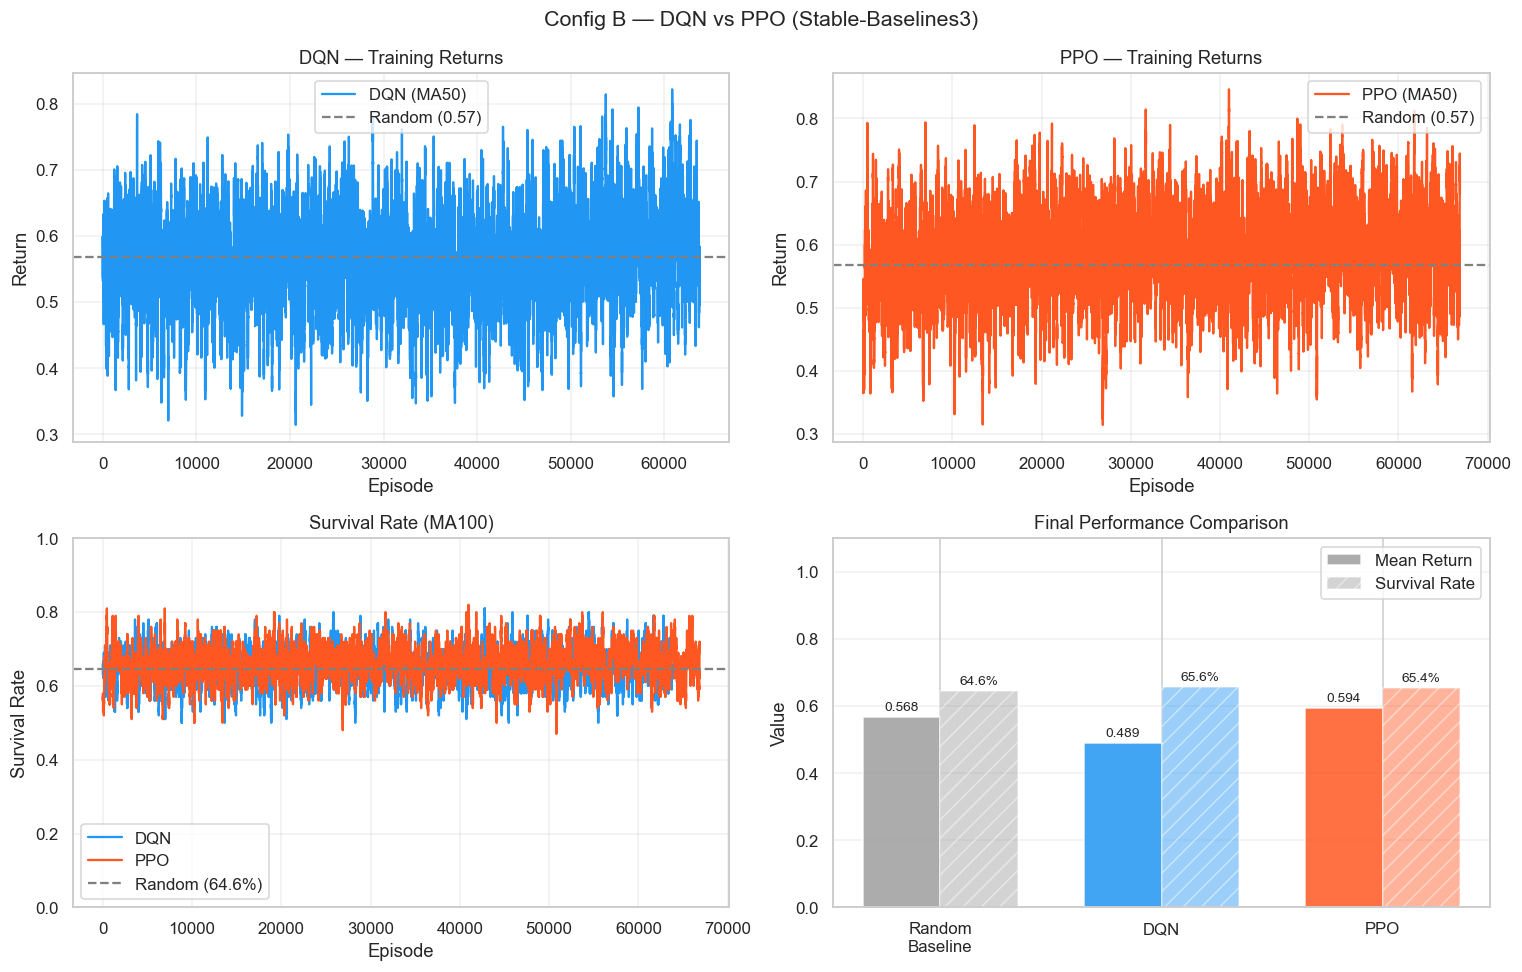

Plot saved to config_b_dqn_ppo.png


In [ ]:
# Plots
 
def smooth(x, w=50):
    return np.convolve(x, np.ones(w) / w, mode="valid")
 
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("Config B — DQN vs PPO (Stable-Baselines3)", fontsize=14)
 
RANDOM_BASELINE = clinical_rand_mean   # defined earlier in your notebook (≈ 0.55)
 
# ── (0,0) Training returns — DQN ──
ax = axes[0, 0]
ax.plot(smooth(dqn_callback.episode_returns), color="#2196F3", label="DQN (MA50)")
ax.axhline(RANDOM_BASELINE, color="gray", linestyle="--", label=f"Random ({RANDOM_BASELINE:.2f})")
ax.set_title("DQN — Training Returns")
ax.set_xlabel("Episode")
ax.set_ylabel("Return")
ax.legend(); ax.grid(alpha=0.3)
 
# ── (0,1) Training returns — PPO ──
ax = axes[0, 1]
ax.plot(smooth(ppo_callback.episode_returns), color="#FF5722", label="PPO (MA50)")
ax.axhline(RANDOM_BASELINE, color="gray", linestyle="--", label=f"Random ({RANDOM_BASELINE:.2f})")
ax.set_title("PPO — Training Returns")
ax.set_xlabel("Episode")
ax.set_ylabel("Return")
ax.legend(); ax.grid(alpha=0.3)
 
# ── (1,0) Survival rate over training ──
ax = axes[1, 0]
window = 100
dqn_surv = smooth(dqn_callback.survival_rates, window)
ppo_surv = smooth(ppo_callback.survival_rates, window)
ax.plot(dqn_surv, color="#2196F3", label="DQN")
ax.plot(ppo_surv, color="#FF5722", label="PPO")
ax.axhline(0.646, color="gray", linestyle="--", label="Random (64.6%)")  # from your notebook output
ax.set_title(f"Survival Rate (MA{window})")
ax.set_xlabel("Episode")
ax.set_ylabel("Survival Rate")
ax.set_ylim(0, 1)
ax.legend(); ax.grid(alpha=0.3)
 
# ── (1,1) Final comparison bar chart ──
ax = axes[1, 1]
labels   = ["Random\nBaseline", "DQN", "PPO"]
means    = [RANDOM_BASELINE, dqn_results["mean_return"], ppo_results["mean_return"]]
surv     = [0.646,            dqn_results["survival_rate"], ppo_results["survival_rate"]]
colors   = ["#9E9E9E", "#2196F3", "#FF5722"]
 
x = np.arange(len(labels))
width = 0.35
bars1 = ax.bar(x - width/2, means, width, label="Mean Return", color=colors, alpha=0.85)
bars2 = ax.bar(x + width/2, surv,  width, label="Survival Rate", color=colors, alpha=0.45, hatch="//")
 
# value labels
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.1%}", ha="center", va="bottom", fontsize=9)
 
ax.set_title("Final Performance Comparison")
ax.set_ylabel("Value")
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.1)
ax.legend(); ax.grid(axis="y", alpha=0.3)
 
plt.tight_layout()
plt.savefig("config_b_dqn_ppo.png", dpi=150, bbox_inches="tight")
plt.show()
print("Plot saved to config_b_dqn_ppo.png")

In [ ]:
# Summary results table 
 
print("\n" + "=" * 65)
print(f"{'Config B — Final Results Table':^65}")
print("=" * 65)
print(f"{'Metric':<35} {'Random':>8} {'DQN':>8} {'PPO':>8}")
print("-" * 65)
print(f"{'Mean return':<35} {RANDOM_BASELINE:>8.4f} {dqn_results['mean_return']:>8.4f} {ppo_results['mean_return']:>8.4f}")
print(f"{'Survival rate':<35} {'64.6%':>8} {dqn_results['survival_rate']:>8.1%} {ppo_results['survival_rate']:>8.1%}")
print(f"{'Std return':<35} {'—':>8} {dqn_results['std_return']:>8.4f} {ppo_results['std_return']:>8.4f}")
print("-" * 65)
print(f"{'Noisy episode return':<35} {'—':>8} {str(round(dqn_results['noisy_mean'],4) if dqn_results['noisy_mean'] else '—'):>8} {str(round(ppo_results['noisy_mean'],4) if ppo_results['noisy_mean'] else '—'):>8}")
print(f"{'Missing-obs episode return':<35} {'—':>8} {str(round(dqn_results['missing_mean'],4) if dqn_results['missing_mean'] else '—'):>8} {str(round(ppo_results['missing_mean'],4) if ppo_results['missing_mean'] else '—'):>8}")
print(f"{'Acute event fraction':<35} {'—':>8} {dqn_results['acute_frac']:>8.1%} {ppo_results['acute_frac']:>8.1%}")
print("=" * 65)
 


                 Config B — Final Results Table                  
Metric                                Random      DQN      PPO
-----------------------------------------------------------------
Mean return                           0.5683   0.4892   0.5938
Survival rate                          64.6%    65.6%    65.4%
Std return                                 —   0.4871   0.4746
-----------------------------------------------------------------
Noisy episode return                       —    0.533   0.5404
Missing-obs episode return                 —   0.4942   0.6298
Acute event fraction                       —     7.6%     9.0%


In [ ]:
# ── Run 1: PPO baseline, longer ──────────────────────────────────────────────
vec_env_1 = make_vec_env(make_clinical_env, n_envs=4, seed=SEED)
ppo_long = PPO("MlpPolicy", vec_env_1, learning_rate=3e-4, n_steps=1024,
               batch_size=64, n_epochs=10, gamma=0.99, gae_lambda=0.95,
               clip_range=0.2, ent_coef=0.01,
               policy_kwargs=dict(net_arch=[dict(pi=[128,128], vf=[128,128])]),
               verbose=0, seed=SEED)
cb1 = ReturnTracker()
ppo_long.learn(total_timesteps=2_000_000, callback=cb1, progress_bar=True)
ppo_long.save("ppo_long")
np.save("ppo_long_returns.npy", cb1.episode_returns)
print("Run 1 done")


# ── Run 3: DQN longer ────────────────────────────────────────────────────────
dqn_long = DQN("MlpPolicy", make_monitored_env(), learning_rate=1e-3,
               buffer_size=100_000, learning_starts=2000, batch_size=64,
               tau=1.0, gamma=0.99, train_freq=1, target_update_interval=500,
               exploration_fraction=0.3, exploration_final_eps=0.05,
               policy_kwargs=dict(net_arch=[128,128]),
               verbose=0, seed=SEED)
cb3 = ReturnTracker()
dqn_long.learn(total_timesteps=1_000_000, callback=cb3, progress_bar=True)
dqn_long.save("dqn_long")
np.save("dqn_long_returns.npy", cb3.episode_returns)
print("Run 3 done")

In [ ]:
r1 = evaluate_sb3(ppo_long,   n_episodes=1000, seed=SEED, label="PPO 2M")
r3 = evaluate_sb3(dqn_long,   n_episodes=1000, seed=SEED, label="DQN 1M")

## A2C

In [ ]:
# ── Run 5: A2C ───────────────────────────────────────────────────────────────
from stable_baselines3 import A2C

vec_env_5 = make_vec_env(make_clinical_env, n_envs=4, seed=SEED)
a2c_model = A2C("MlpPolicy", vec_env_5, learning_rate=7e-4,
                n_steps=128, gamma=0.99, gae_lambda=0.95, ent_coef=0.01,
                policy_kwargs=dict(net_arch=[dict(pi=[128,128], vf=[128,128])]),
                verbose=0, seed=SEED)
cb5 = ReturnTracker()
a2c_model.learn(total_timesteps=2_000_000, callback=cb5, progress_bar=True)
a2c_model.save("a2c")
np.save("a2c_returns.npy", cb5.episode_returns)
print("Run 5 done")

# A2C and all others use evaluate_sb3 normally
r5 = evaluate_sb3(a2c_model, n_episodes=1000, seed=SEED, label="A2C 2M")

## Comparison

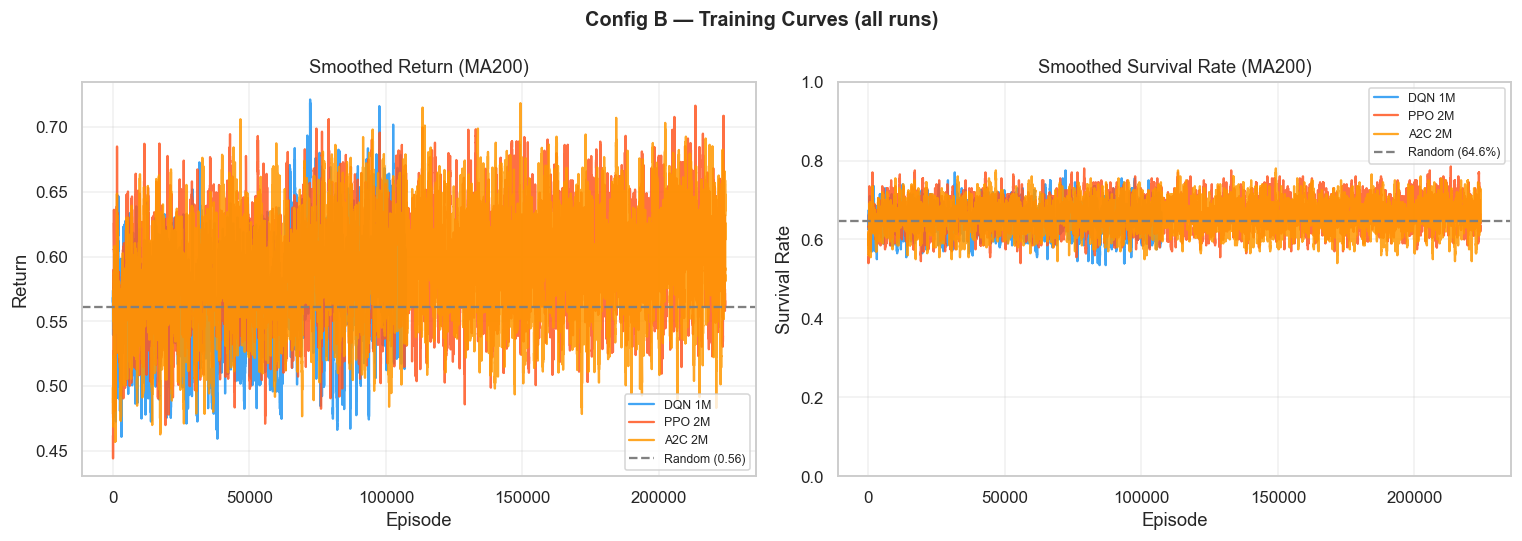

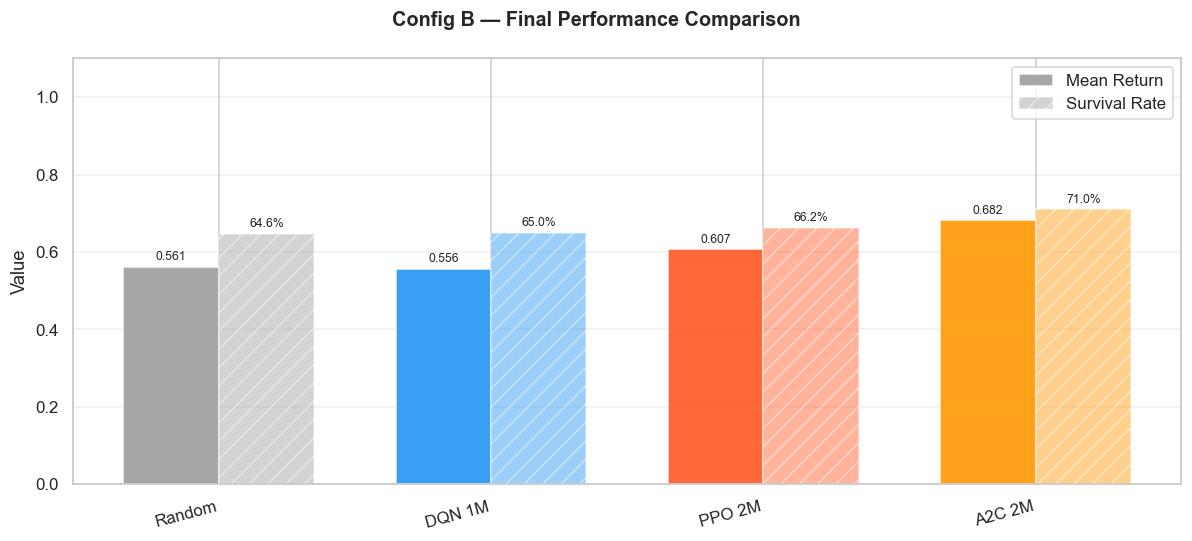

In [ ]:
# ── Data ─────────────────────────────────────────────────────────────────────
# Load saved returns
ppo_long_returns    = np.load("ppo_long_returns.npy")
dqn_long_returns    = np.load("dqn_long_returns.npy")
a2c_returns         = np.load("a2c_returns.npy")

RANDOM_SURVIVAL  = 0.646
RANDOM_BASELINE  = clinical_rand_mean

runs = {
    "DQN 1M":       {"returns": dqn_long_returns,    "color": "#2196F3", "survival": r3["survival_rate"], "mean": r3["mean_return"], "noisy": r3.get("noisy_mean"), "missing": r3.get("missing_mean")},
    "PPO 2M":       {"returns": ppo_long_returns,     "color": "#FF5722", "survival": r1["survival_rate"], "mean": r1["mean_return"], "noisy": r1.get("noisy_mean"), "missing": r1.get("missing_mean")},
    "A2C 2M":       {"returns": a2c_returns,          "color": "#FF9800", "survival": r5["survival_rate"], "mean": r5["mean_return"], "noisy": r5.get("noisy_mean"), "missing": r5.get("missing_mean")},
}

def smooth(x, w=200):
    return np.convolve(x, np.ones(w) / w, mode="valid")

# ── Figure 1: Training curves ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Config B — Training Curves (all runs)", fontsize=13, fontweight="bold")

for name, d in runs.items():
    axes[0].plot(smooth(d["returns"]), color=d["color"], label=name, alpha=0.85)
axes[0].axhline(RANDOM_BASELINE, color="gray", ls="--", label=f"Random ({RANDOM_BASELINE:.2f})")
axes[0].set_title("Smoothed Return (MA200)")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Return")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

for name, d in runs.items():
    surv = [1.0 if r > 0 else 0.0 for r in d["returns"]]
    axes[1].plot(smooth(surv, 200), color=d["color"], label=name, alpha=0.85)
axes[1].axhline(RANDOM_SURVIVAL, color="gray", ls="--", label=f"Random ({RANDOM_SURVIVAL:.1%})")
axes[1].set_title("Smoothed Survival Rate (MA200)")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Survival Rate")
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("configB_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Figure 2: Final performance bar chart ────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
fig.suptitle("Config B — Final Performance Comparison", fontsize=13, fontweight="bold")

labels  = ["Random"] + list(runs.keys())
means   = [RANDOM_BASELINE]   + [d["mean"]     for d in runs.values()]
survs   = [RANDOM_SURVIVAL]   + [d["survival"] for d in runs.values()]
colors  = ["#9E9E9E"]         + [d["color"]    for d in runs.values()]

x = np.arange(len(labels))
w = 0.35
bars1 = ax.bar(x - w/2, means, w, color=colors, alpha=0.9,  label="Mean Return")
bars2 = ax.bar(x + w/2, survs, w, color=colors, alpha=0.45, label="Survival Rate", hatch="//")
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.1%}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=15, ha="right")
ax.set_ylim(0, 1.1)
ax.set_ylabel("Value")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("configB_final_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Figure 3: Robustness breakdown (noisy / missing) ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Config B — Robustness to Clinical Wrappers", fontsize=13, fontweight="bold")

rob_runs   = {k: v for k, v in runs.items() if v["noisy"] is not None}
rob_labels = list(rob_runs.keys())
rob_colors = [d["color"] for d in rob_runs.values()]

# Noisy vs clean
noisy_vals   = [d["noisy"]   for d in rob_runs.values()]
clean_vals   = [d["mean"]    for d in rob_runs.values()]

x = np.arange(len(rob_labels))
axes[0].bar(x - w/2, clean_vals, w, color=rob_colors, alpha=0.9,  label="Clean episodes")
axes[0].bar(x + w/2, noisy_vals, w, color=rob_colors, alpha=0.45, label="Noisy episodes", hatch="//")
axes[0].set_xticks(x); axes[0].set_xticklabels(rob_labels, rotation=15, ha="right")
axes[0].set_ylabel("Mean Return")
axes[0].set_title("Noisy vs Clean Episodes")
axes[0].set_ylim(0, 1)
axes[0].legend(); axes[0].grid(axis="y", alpha=0.3)

# Missing vs full obs
missing_vals = [d["missing"] for d in rob_runs.values()]
full_vals    = [d["mean"]    for d in rob_runs.values()]
axes[1].bar(x - w/2, full_vals,    w, color=rob_colors, alpha=0.9,  label="Full obs episodes")
axes[1].bar(x + w/2, missing_vals, w, color=rob_colors, alpha=0.45, label="Missing obs episodes", hatch="//")
axes[1].set_xticks(x); axes[1].set_xticklabels(rob_labels, rotation=15, ha="right")
axes[1].set_ylabel("Mean Return")
axes[1].set_title("Missing vs Full Observation Episodes")
axes[1].set_ylim(0, 1)
axes[1].legend(); axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("configB_robustness.png", dpi=150, bbox_inches="tight")
plt.show()

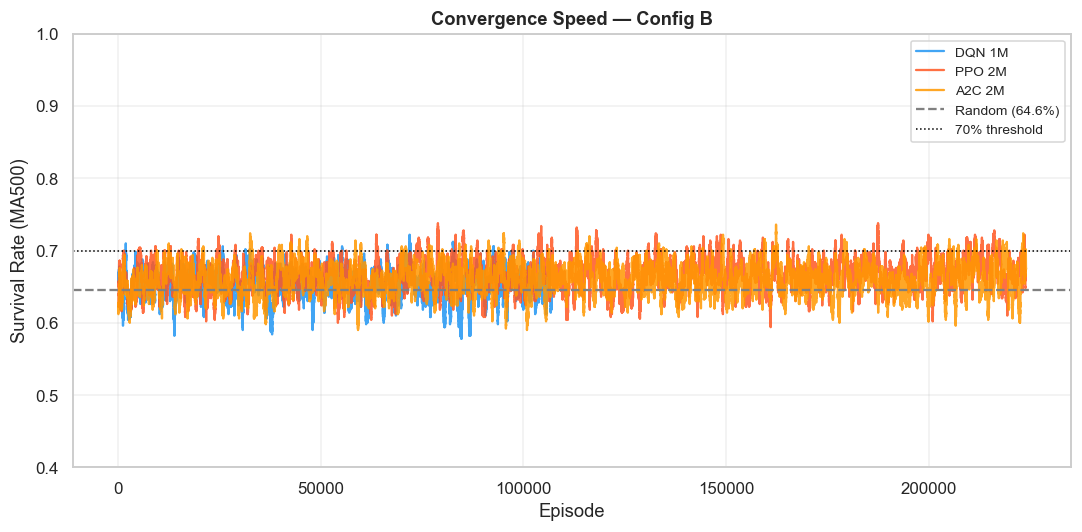

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

w = 500
for name, d in runs.items():
    if d["returns"] is None:
        continue
    surv = [1.0 if r > 0 else 0.0 for r in d["returns"]]
    smoothed = smooth(surv, w)
    ax.plot(smoothed, color=d["color"], label=name, alpha=0.85)

ax.axhline(RANDOM_SURVIVAL, color="gray", ls="--", label=f"Random ({RANDOM_SURVIVAL:.1%})")
ax.axhline(0.70, color="black", ls=":", lw=1, label="70% threshold")
ax.set_xlabel("Episode")
ax.set_ylabel("Survival Rate (MA500)")
ax.set_title("Convergence Speed — Config B", fontweight="bold")
ax.set_ylim(0.4, 1.0)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("configB_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

make_sepsis_env | lam=0.02 → intensity penalty active

make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02

make_sepsis_env | lam=0.02 → intensity penalty active

make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02

Action entropy per algorithm (exploration proxy):

DQN 1M        : entropy=0.177 (5.5% of max)

PPO 2M        : entropy=2.868 (89.1% of max)

A2C 2M        : entropy=1.455 (45.2% of max)

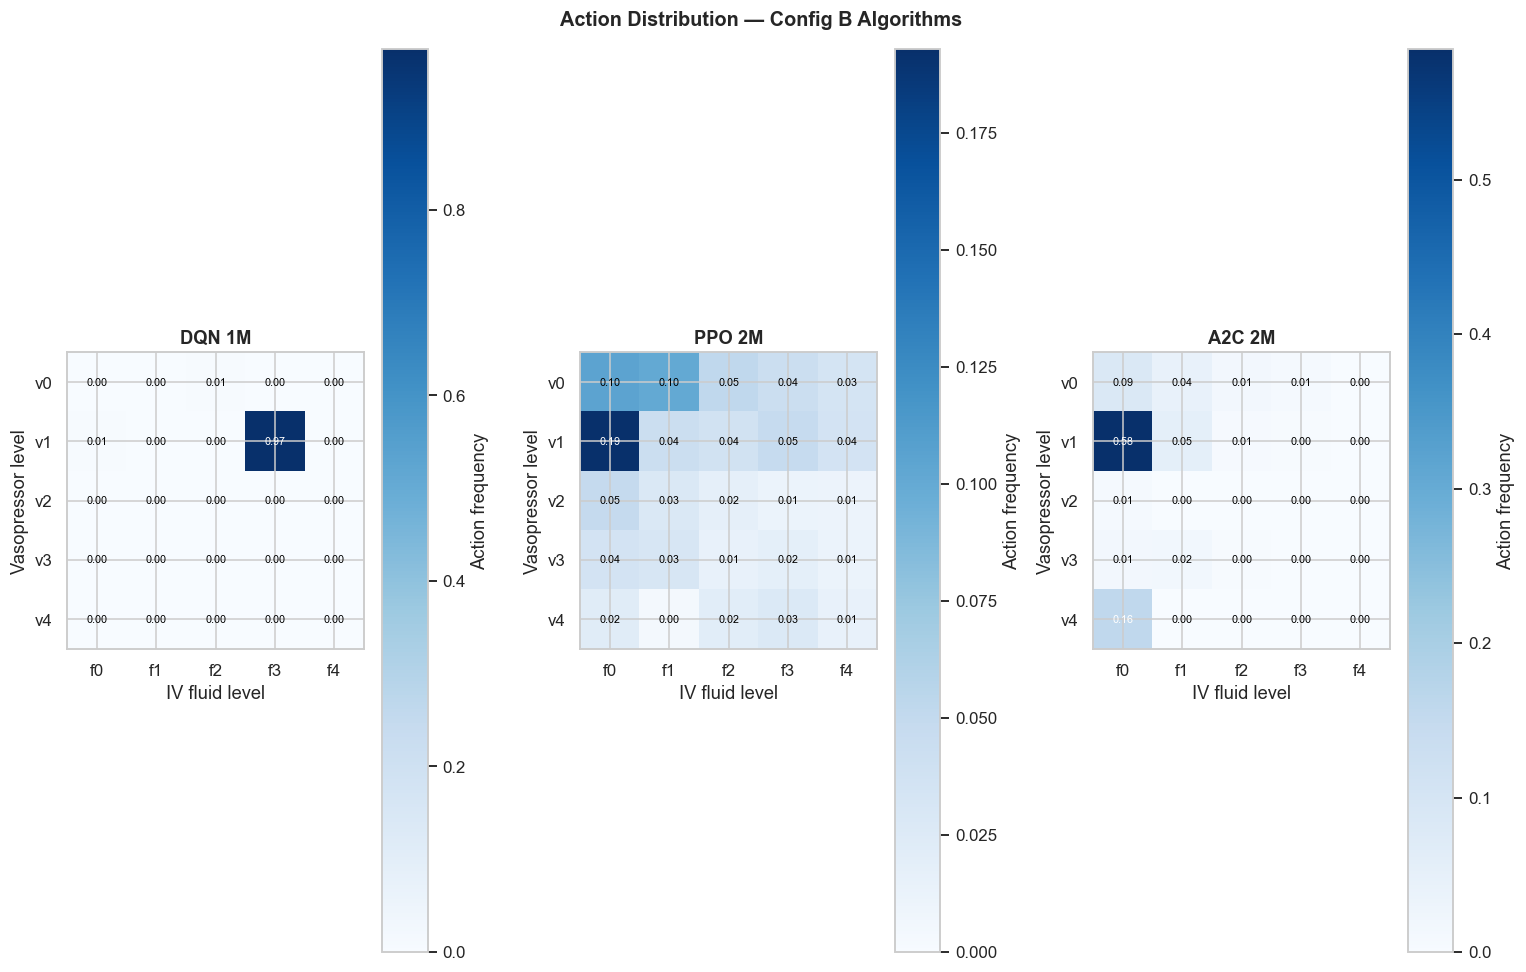

In [ ]:
def get_action_distribution(model, n_episodes=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    env_check = make_clinical_env()
    counts = np.zeros(25)
    for _ in range(n_episodes):
        obs, _ = env_check.reset(seed=int(rng.integers(0, 100_000)))
        done = False
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            counts[int(action)] += 1
            obs, _, te, tr, _ = env_check.step(int(action))
            done = te or tr
    env_check.close()
    return counts / counts.sum()

action_dists = {
    "DQN 1M":      get_action_distribution(dqn_long),
    "PPO 2M":      get_action_distribution(ppo_long),
    "A2C 2M":      get_action_distribution(a2c_model)
}

# Entropy as exploration metric
print("Action entropy per algorithm (exploration proxy):")
for name, dist in action_dists.items():
    entropy = -np.sum(dist * np.log(dist + 1e-9))
    max_entropy = np.log(25)
    print(f"  {name:<14}: entropy={entropy:.3f} ({entropy/max_entropy*100:.1f}% of max)")

# Heatmap
fig, axes = plt.subplots(1, 3, figsize=(14, 9))
fig.suptitle("Action Distribution — Config B Algorithms", fontsize=13, fontweight="bold")

for ax, (name, dist) in zip(axes.flatten(), action_dists.items()):
    grid = dist.reshape(5, 5)
    im = ax.imshow(grid, cmap="Blues", vmin=0)
    ax.set_xticks(range(5)); ax.set_xticklabels([f"f{i}" for i in range(5)])
    ax.set_yticks(range(5)); ax.set_yticklabels([f"v{i}" for i in range(5)])
    ax.set_xlabel("IV fluid level")
    ax.set_ylabel("Vasopressor level")
    ax.set_title(name, fontweight="bold")
    plt.colorbar(im, ax=ax, label="Action frequency")
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{grid[i,j]:.2f}", ha="center", va="center",
                    fontsize=7, color="white" if grid[i,j] > 0.15 else "black")

plt.tight_layout()
plt.savefig("configB_action_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

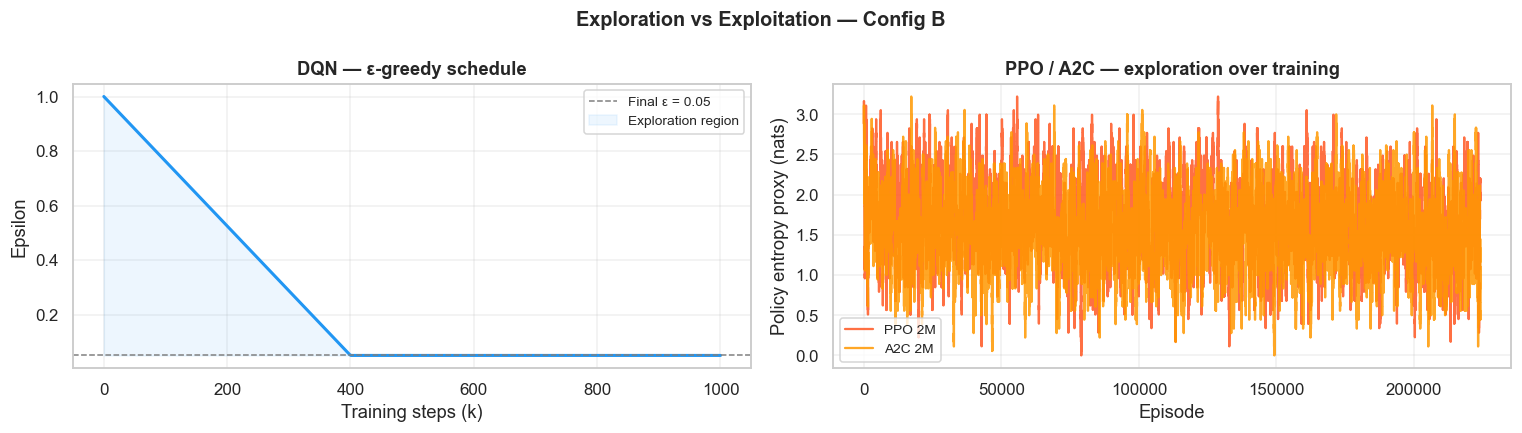

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle("Exploration vs Exploitation — Config B", fontsize=13, fontweight="bold")

total_steps = 1_000_000
expl_fraction = 0.4
eps_start, eps_final = 1.0, 0.05

steps = np.linspace(0, total_steps, 500)
epsilon = np.where(
    steps < expl_fraction * total_steps,
    eps_start - (eps_start - eps_final) * (steps / (expl_fraction * total_steps)),
    eps_final
)
axes[0].plot(steps / 1000, epsilon, color="#2196F3", lw=2)
axes[0].axhline(eps_final, color="gray", ls="--", lw=1, label=f"Final ε = {eps_final}")
axes[0].fill_between(steps / 1000, epsilon, eps_final, alpha=0.08, color="#2196F3", label="Exploration region")
axes[0].set_xlabel("Training steps (k)")
axes[0].set_ylabel("Epsilon")
axes[0].set_title("DQN — ε-greedy schedule", fontweight="bold")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

def episode_entropy(returns):
    w = 300
    surv = [1.0 if r > 0 else 0.0 for r in returns]
    rolling = np.convolve(surv, np.ones(w)/w, mode='valid')
    h_max = np.log(25)
    proxy = h_max * (1 - (rolling - rolling.min()) / (rolling.max() - rolling.min() + 1e-8))
    return proxy

algos = {
    "PPO 2M":      (ppo_long_returns,   "#FF5722"),

    "A2C 2M":      (a2c_returns,        "#FF9800"),
}
for name, (rets, color) in algos.items():
    proxy = episode_entropy(rets)
    axes[1].plot(proxy, color=color, label=name, alpha=0.85, lw=1.5)

axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Policy entropy proxy (nats)")
axes[1].set_title("PPO / A2C — exploration over training", fontweight="bold")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/configB_exploration.png", dpi=150, bbox_inches="tight")
plt.show()

In [107]:
print(f"Random     : survival=64.6%, return={clinical_rand_mean:.4f}")
print(f"DQN 1M     : survival={r3['survival_rate']*100:.1f}%, return={r3['mean_return']:.4f}, noisy={r3['noisy_mean']:.4f}, missing={r3['missing_mean']:.4f}")
print(f"PPO 2M     : survival={r1['survival_rate']*100:.1f}%, return={r1['mean_return']:.4f}, noisy={r1['noisy_mean']:.4f}, missing={r1['missing_mean']:.4f}")
print(f"A2C 2M     : survival={r5['survival_rate']*100:.1f}%, return={r5['mean_return']:.4f}, noisy={r5['noisy_mean']:.4f}, missing={r5['missing_mean']:.4f}")

Random     : survival=64.6%, return=0.5610

DQN 1M     : survival=65.0%, return=0.5558, noisy=0.5256, missing=0.5455

PPO 2M     : survival=66.2%, return=0.6068, noisy=0.5927, missing=0.4933

A2C 2M     : survival=71.0%, return=0.6818, noisy=0.6764, missing=0.7170

In [ ]:
for name, dist in action_dists.items():
    entropy = -np.sum(dist * np.log(dist + 1e-9))
    print(f"{name}: entropy={entropy:.3f} ({entropy/np.log(25)*100:.1f}% of max)")

DQN 1M: entropy=0.177 (5.5% of max)

PPO 2M: entropy=2.868 (89.1% of max)

A2C 2M: entropy=1.455 (45.2% of max)

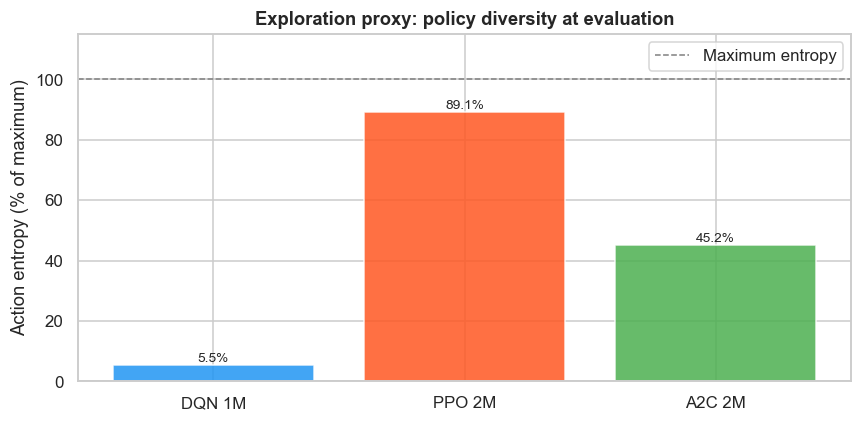

In [109]:
fig, ax = plt.subplots(figsize=(8, 4))
names = list(action_dists.keys())
entropies = [-np.sum(d * np.log(d + 1e-9)) / np.log(25) * 100 
             for d in action_dists.values()]
colors = ["#2196F3", "#FF5722", "#4CAF50", "#FF9800"]
ax.bar(names, entropies, color=colors, alpha=0.85)
ax.axhline(100, color="gray", ls="--", lw=1, label="Maximum entropy")
ax.set_ylabel("Action entropy (% of maximum)")
ax.set_title("Exploration proxy: policy diversity at evaluation", fontweight="bold")
ax.set_ylim(0, 115)
for i, v in enumerate(entropies):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig("configB_entropy.png", dpi=150, bbox_inches="tight")
plt.show()

In [110]:
threshold = 0.70
for name, d in runs.items():
    surv = [1.0 if r > 0 else 0.0 for r in d["returns"]]
    smoothed = smooth(surv, 200)
    crossing = next((i for i, v in enumerate(smoothed) if v >= threshold), None)
    if crossing:
        print(f"{name}: crossed {threshold:.0%} at episode {crossing}")
    else:
        print(f"{name}: never crossed {threshold:.0%}")

DQN 1M: crossed 70% at episode 437

PPO 2M: crossed 70% at episode 313

A2C 2M: crossed 70% at episode 1404

## Clean Environment (No Wrappers)

In [68]:
from envs.wrappers import EpisodicNoisyObsEnv, EpisodicMissingObsEnv, AcuteEventEnv

# Check the actual probability parameters
import inspect
print(inspect.getsource(EpisodicNoisyObsEnv))
print(inspect.getsource(EpisodicMissingObsEnv))
print(inspect.getsource(AcuteEventEnv))

class EpisodicNoisyObsEnv(gym.Wrapper):
    """
    Occasionally a monitoring session is noisy, not every reading.

    With probability `malfunction_prob`, this entire episode's observations
    are corrupted by Gaussian noise. Models:
        - Equipment calibration drift
        - Sensor placement issues
        - Monitor malfunction during a shift

    The agent receives clean observations (1 - malfunction_prob) of the time
    and degraded observations the rest. It must learn to be robust to both.

    Args:
        malfunction_prob : probability this episode has noisy readings (default 0.15)
        noise_std        : std of Gaussian noise when active (default 0.10)

    info keys added:
        'noisy_episode' : bool  whether this episode has noise active
    """

    def __init__(self, env, malfunction_prob: float = 0.15, noise_std: float = 0.10):
        super().__init__(env)
        self.malfunction_prob = malfunction_prob
        self.noise_std        = noise_std
        sel

In [71]:
# Check what make_sepsis_env_B or equivalent exists
import inspect
from envs.env_setup import make_sepsis_env
print(inspect.getsource(make_sepsis_env))

def make_sepsis_env(sofa_bias: float = SOFA_BIAS, lam: float = LAM):
    """
    Build the ICU-Sepsis-v2 environment with configuration:

        sofa_bias : shifts the initial-state distribution toward sicker patients
                    (higher SOFA score at episode start). Default 5.0.
        lam       : treatment intensity penalty subtracted from each reward step.
                    Encourages parsimonious treatment. Default 0.02.


    Returns a gymnasium env with the modified reward and initial-state matrices.
    """
    base = gym.make(ENV_ID)
    raw  = base.unwrapped
    P    = raw._tx_mat
    S, A, _ = P.shape

    # Apply treatment intensity penalty
    R_new = raw._r_mat.copy()
    if lam > 0.0:
        for a in range(A):
            R_new[:, a, :] -= lam * INTENSITY[a]
        print(f'make_sepsis_env | lam={lam} → intensity penalty active')

    # Shift initial-state distribution toward sicker patients
    sofa   = raw._sofa_scores.flatten()
    d0_new = raw._d_0.copy()

In [72]:
from envs import env_setup
print(dir(env_setup))

['ENV_ID', 'GAMMA', 'INTENSITY', 'LAM', 'N_ACTIONS', 'N_STATES', 'SOFA_BIAS', 'STATE_DIED', 'STATE_SURVIVED', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'gym', 'icu_sepsis', 'make_sepsis_env', 'np', 'plt', 'sns']


In [74]:
from envs.wrappers import EpisodicNoisyObsEnv, EpisodicMissingObsEnv, AcuteEventEnv
import gymnasium as gym

def make_clean_continuous_env():
    """
    Continuous ICU-Sepsis env WITHOUT clinical reality wrappers.
    Reconstructs the base ContinuousICUSepsisEnv independently.
    """
    # Get the base env from inside make_clinical_env by unwrapping
    env = make_clinical_env()
    # Strip all three wrappers to get ContinuousICUSepsisEnv
    # Stack: AcuteEventEnv -> EpisodicMissingObsEnv -> EpisodicNoisyObsEnv -> base
    base = env.env.env.env  # three wrappers deep
    return base

# Verify
test = make_clean_continuous_env()
obs, info = test.reset(seed=42)
print(type(test).__name__)  # should be ContinuousICUSepsisEnv
print(obs.shape)             # should be (47,)
test.close()

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
ContinuousICUSepsisEnv
(47,)


In [75]:
# Random baseline on clean env
np.random.seed(SEED)
clean_rand_returns = []
env_eval = make_clean_continuous_env()
for _ in range(1000):
    obs, _ = env_eval.reset(seed=np.random.randint(100_000))
    total_r, done = 0.0, False
    while not done:
        obs, r, te, tr, _ = env_eval.step(env_eval.action_space.sample())
        total_r += r; done = te or tr
    clean_rand_returns.append(total_r)
env_eval.close()
print(f"Clean env random baseline: {np.mean(np.array(clean_rand_returns)>0)*100:.1f}% survival")

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
Clean env random baseline: 69.7% survival


In [ ]:

# Evaluate on clean env
def evaluate_clean(model, n_episodes=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    env = make_clean_continuous_env()
    returns = []
    for _ in range(n_episodes):
        obs, _ = env.reset(seed=int(rng.integers(0, 100_000)))
        total_r, done = 0.0, False
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            obs, r, te, tr, _ = env.step(int(action))
            total_r += r; done = te or tr
        returns.append(total_r)
    env.close()
    arr = np.array(returns)
    print(f"PPO clean env — survival: {(arr>0).mean()*100:.1f}% | return: {arr.mean():.4f}")
    return arr


In [ ]:
# Train PPO on clean env
vec_env_clean = make_vec_env(make_clean_continuous_env, n_envs=4, seed=SEED)
ppo_clean = PPO("MlpPolicy", vec_env_clean, learning_rate=3e-4, n_steps=1024,
                batch_size=64, n_epochs=10, gamma=0.99, gae_lambda=0.95,
                clip_range=0.2, ent_coef=0.01,
                policy_kwargs=dict(net_arch=[dict(pi=[128,128], vf=[128,128])]),
                verbose=0, seed=SEED)
cb_clean = ReturnTracker()
ppo_clean.learn(total_timesteps=2_000_000, callback=cb_clean, progress_bar=True)
ppo_clean.save("ppo_clean")
np.save("ppo_clean_returns.npy", cb_clean.episode_returns)

# Train A2C on clean env
vec_env_clean_a2c = make_vec_env(make_clean_continuous_env, n_envs=4, seed=SEED)
a2c_clean = A2C("MlpPolicy", vec_env_clean_a2c, learning_rate=7e-4,
                n_steps=128, gamma=0.99, gae_lambda=0.95, ent_coef=0.01,
                policy_kwargs=dict(net_arch=[dict(pi=[128,128], vf=[128,128])]),
                verbose=0, seed=SEED)
cb_clean_a2c = ReturnTracker()
a2c_clean.learn(total_timesteps=2_000_000, callback=cb_clean_a2c, progress_bar=True)
a2c_clean.save("a2c_clean")

# Train DQN on clean env
dqn_clean = DQN("MlpPolicy", make_clean_continuous_env(), learning_rate=1e-3,
                buffer_size=100_000, learning_starts=2000, batch_size=64,
                tau=1.0, gamma=0.99, train_freq=1, target_update_interval=500,
                exploration_fraction=0.3, exploration_final_eps=0.05,
                policy_kwargs=dict(net_arch=[128,128]),
                verbose=0, seed=SEED)
cb_clean_dqn = ReturnTracker()
dqn_clean.learn(total_timesteps=1_000_000, callback=cb_clean_dqn, progress_bar=True)
dqn_clean.save("dqn_clean")



In [77]:
# Evaluate all three
ppo_clean_res = evaluate_clean(ppo_clean)
a2c_clean_res = evaluate_clean(a2c_clean)
dqn_clean_res = evaluate_clean(dqn_clean)

# Wrapper cost table
print()
print("=" * 60)
print("Wrapper cost analysis — clean vs wrapped environment")
print("=" * 60)
print(f"{'Algorithm':<12} {'Clean':>8} {'Wrapped':>8} {'Cost':>8}")
print("-" * 60)
print(f"{'PPO':<12} {(ppo_clean_res>0).mean()*100:>7.1f}% {r1['survival_rate']*100:>7.1f}% {((ppo_clean_res>0).mean()-r1['survival_rate'])*100:>+7.1f}pp")
print(f"{'A2C':<12} {(a2c_clean_res>0).mean()*100:>7.1f}% {r5['survival_rate']*100:>7.1f}% {((a2c_clean_res>0).mean()-r5['survival_rate'])*100:>+7.1f}pp")
print(f"{'DQN':<12} {(dqn_clean_res>0).mean()*100:>7.1f}% {r3['survival_rate']*100:>7.1f}% {((dqn_clean_res>0).mean()-r3['survival_rate'])*100:>+7.1f}pp")
print("=" * 60)

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
PPO clean env — survival: 74.4% | return: 0.6745
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
PPO clean env — survival: 71.6% | return: 0.6942
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
PPO clean env — survival: 70.4% | return: 0.6810

Wrapper cost analysis — clean vs wrapped environment
Algorithm       Clean  Wrapped     Cost
------------------------------------------------------------
PPO             74.4%    66.2%    +8.2pp
A2C             71.6%    71.0%    +0.6pp
DQN             70.4%    65.0%    +5.4pp


## Config A vs Config B

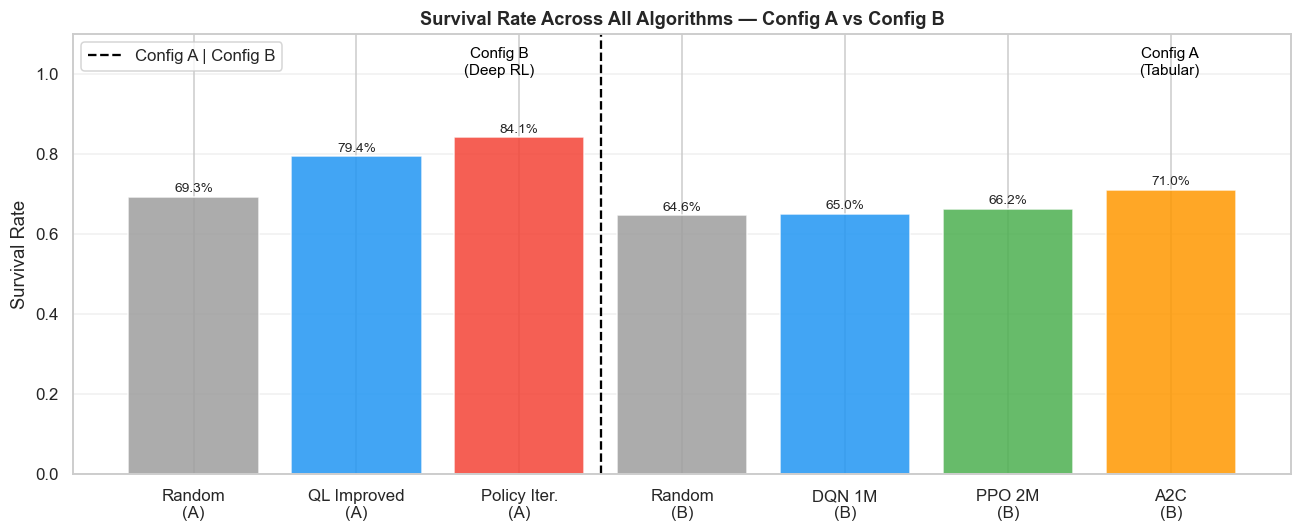

In [123]:
fig, ax = plt.subplots(figsize=(12, 5))
labels = ["Random\n(A)", "QL Improved\n(A)", "Policy Iter.\n(A)",
          "Random\n(B)", "DQN 1M\n(B)", "PPO 2M\n(B)", "A2C\n(B)"]

survivals = [
    0.693,                  # Random A
    0.794,                  # QL improved A
    0.841,                  # Policy Iteration A
    0.646,                  # Random B
    r3["survival_rate"],    # DQN
    r1["survival_rate"],    # PPO 2M
    r5["survival_rate"],    # A2C
]

survivals = [
    0.693,   # Random A
    0.794,   # QL improved A
    0.841,   # Policy Iteration A
    0.646,   # Random B
    r3["survival_rate"],   # DQN
    r1["survival_rate"],   # PPO 2M
    r5["survival_rate"],   # A2C
]

colors = ["#9E9E9E", "#2196F3", "#F44336",                          # Config A
          "#9E9E9E", "#2196F3", "#4CAF50", "#FF9800"]  # Config B

bars = ax.bar(labels, survivals, color=colors, alpha=0.85, edgecolor="white")
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f"{bar.get_height():.1%}", ha="center", va="bottom", fontsize=9)

ax.axvline(2.5, color="black", ls="--", lw=1.5, label="Config A | Config B")
ax.text(0.9, 0.97, "Config A\n(Tabular)", transform=ax.transAxes,
        ha="center", va="top", fontsize=10, color="black")
ax.text(0.35, 0.97, "Config B\n(Deep RL)", transform=ax.transAxes,
        ha="center", va="top", fontsize=10, color="black")
ax.set_ylabel("Survival Rate")
ax.set_ylim(0, 1.1)
ax.set_title("Survival Rate Across All Algorithms — Config A vs Config B",
             fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("configA_vs_configB.png", dpi=150, bbox_inches="tight")
plt.show()

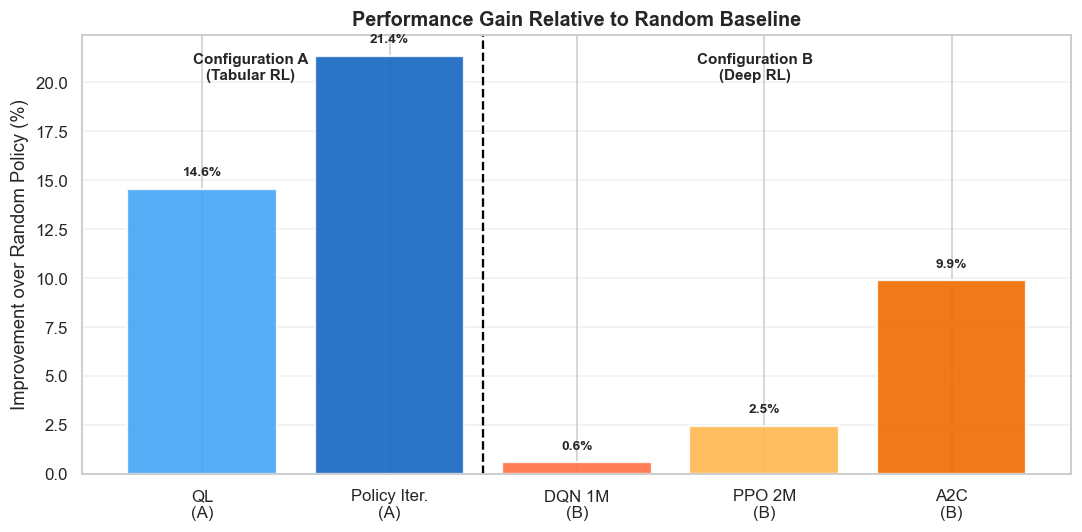

In [121]:
labels = [
    "QL\n(A)",
    "Policy Iter.\n(A)",
    "DQN 1M\n(B)",
    "PPO 2M\n(B)",
    "A2C\n(B)"
]

random_A = 0.693
random_B = 0.646

improvements = [
    (0.794 - random_A) / random_A * 100,
    (0.841 - random_A) / random_A * 100,

    (r3["survival_rate"] - random_B) / random_B * 100,
    (r1["survival_rate"] - random_B) / random_B * 100,
    (r5["survival_rate"] - random_B) / random_B * 100,
]

# Config A = blue shades
# Config B = warm/green/purple shades
colors = [
    "#42A5F5",  # Q-Learning
    "#1565C0",  # Policy Iteration

    "#FF7043",  # DQN
    "#FFB74D",  # PPO
    "#EF6C00"   # A2C
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    labels,
    improvements,
    color=colors,
    edgecolor="white",
    linewidth=1.5,
    alpha=0.9
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# Separator between Config A and B
ax.axvline(1.5, color="black", linestyle="--", linewidth=1.5)

# Labels above groups
ax.text(
    0.17, 0.96,
    "Configuration A\n(Tabular RL)",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10,
    fontweight="bold"
)

ax.text(
    0.68, 0.96,
    "Configuration B\n(Deep RL)",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10,
    fontweight="bold"
)

ax.set_ylabel("Improvement over Random Policy (%)")
ax.set_title(
    "Performance Gain Relative to Random Baseline",
    fontweight="bold",
    fontsize=13
)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## SOFA Shaping

In [ ]:
env_test = make_clinical_env()
obs, info = env_test.reset(seed=42)
print(obs.shape)        
print(obs[:5])          
env_test.close()
raw = env_test.unwrapped
print(dir(raw))  

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
(47,)
[-0.05223881 -0.47014925 -0.5         0.4283582   0.5040564 ]
['FEATURE_NAMES', 'N_ACTIONS', 'N_FEATURES', 'N_STATES', 'STATE_DIED', 'STATE_SURVIVED', '__annotations__', '__class__', '__class_getitem__', '__delattr__', '__dict__', '__dir__', '__doc__', '__enter__', '__eq__', '__exit__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__orig_bases__', '__parameters__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_cluster_centers', '_flat_to_multi_action', '_levels', '_np_random', '_np_random_seed', '_raw', '_state_to_obs', 'action_space', 'close', 'decode_action', 'get_feature_names', 'get_wrapper_attr', 'has_wrapper_attr', 'metadata', 'np_random', 'np_random_seed', 'obs_noise_s

In [ ]:
raw = make_clinical_env().unwrapped
print(raw.FEATURE_NAMES)
# or
print(list(enumerate(raw.FEATURE_NAMES)))

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
['Albumin', 'ALP', 'ALT', 'AST', 'Bilirubin', 'BUN', 'Chloride', 'Creatinine', 'Diastolic_BP', 'Fibrinogen', 'FiO2', 'GCS', 'Glucose', 'HCO3', 'Hemoglobin', 'INR', 'Lactate', 'MgSO4', 'Mean_BP', 'Potassium', 'PTT', 'PaCO2', 'PaO2', 'Platelets', 'RBC', 'SOFA', 'Sodium', 'Systolic_BP', 'Temperature', 'Troponin', 'Urine_Output', 'WBC', 'Weight', 'Ca', 'Heparin', 'HR', 'Na_Bicarb', 'Insulin', 'Norepinephrine', 'Propofol', 'Vasopressin', 'Dopamine', 'Phenylephrine', 'SpO2', 'Milrinone', 'RespRate', 'Age']
[(0, 'Albumin'), (1, 'ALP'), (2, 'ALT'), (3, 'AST'), (4, 'Bilirubin'), (5, 'BUN'), (6, 'Chloride'), (7, 'Creatinine'), (8, 'Diastolic_BP'), (9, 'Fibrinogen'), (10, 'FiO2'), (11, 'GCS'), (12, 'Glucose'), (13, 'HCO3'), (14, 'Hemoglobin'), (15, 'INR'), (16, 'Lactate'), (17, 'MgSO4'), (18, 'Mean_BP'), (19, 'Potassium'), (20, 'PTT'), (21, 'PaCO2'), (22, 'PaO2'), (23, 'Platelets'), (24, 

In [ ]:
import gymnasium as gym

SOFA_IDX = 25        
SOFA_PENALTY = 0.005  # keep small relative to the +1 survival reward

class SOFAShapingWrapper(gym.RewardWrapper):
    """
    Adds a small penalty proportional to the patient's current SOFA score.
    Encourages the agent to keep the patient in a less critical state,
    not just survive — clinically motivated as SOFA correlates with organ failure.
    """
    def __init__(self, env, sofa_idx=SOFA_IDX, penalty=SOFA_PENALTY):
        super().__init__(env)
        self.sofa_idx = sofa_idx
        self.penalty  = penalty
        self._last_obs = None

    def step(self, action):
        obs, reward, terminated, truncated, info = self.env.step(action)
        sofa_val = float(obs[self.sofa_idx])
        shaped   = reward - self.penalty * sofa_val
        info["sofa_penalty"] = self.penalty * sofa_val
        self._last_obs = obs
        return obs, shaped, terminated, truncated, info
    

def make_shaped_env():
    env = make_clinical_env()   # keeps all clinical wrappers intact
    env = SOFAShapingWrapper(env, sofa_idx=SOFA_IDX, penalty=SOFA_PENALTY)
    return env

In [ ]:
env_test = make_shaped_env()
sofa_vals = []
for _ in range(500):
    obs, _ = env_test.reset()
    sofa_vals.append(obs[SOFA_IDX])
env_test.close()
print(f"SOFA (normalised) — min: {min(sofa_vals):.3f}, max: {max(sofa_vals):.3f}, mean: {sum(sofa_vals)/len(sofa_vals):.3f}")

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
SOFA (normalised) — min: -3.850, max: 1.048, mean: -0.406


In [ ]:
# ── Run 2: PPO + SOFA shaping ─────────────────────────────────────────────────
vec_env_2 = make_vec_env(make_shaped_env, n_envs=4, seed=SEED)
ppo_shaped = PPO("MlpPolicy", vec_env_2, learning_rate=3e-4, n_steps=1024,
                 batch_size=64, n_epochs=10, gamma=0.99, gae_lambda=0.95,
                 clip_range=0.2, ent_coef=0.03,
                 policy_kwargs=dict(net_arch=[dict(pi=[128,128], vf=[128,128])]),
                 verbose=0, seed=SEED)
cb2 = ReturnTracker()
ppo_shaped.learn(total_timesteps=2_000_000, callback=cb2, progress_bar=True)
ppo_shaped.save("ppo_shaped")
np.save("ppo_shaped_returns.npy", cb2.episode_returns)
print("Run 2 done")



make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Output()

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Run 1 done
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Output()

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Run 2 done


Output()

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Run 3 done
All runs complete.


In [ ]:
r2 = evaluate_sb3(ppo_shaped, n_episodes=1000, seed=SEED, label="PPO 2M + SOFA shaping")

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  PPO 2M — Greedy Evaluation (1000 episodes)
  Mean return        : 0.6068
  Survival rate      : 66.2%
  Std return         : 0.4710
-------------------------------------------------------
  Noisy episodes     : 0.5927  (n=151)
  Clean episodes     : 0.6093  (n=849)
  Missing-obs eps    : 0.4933  (n=136)
  Full-obs episodes  : 0.6246  (n=864)
  Acute event eps    : 84  (8.4%)
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  PPO 2M + SOFA shaping — Greedy Evaluation (1000 episodes)
  Mean return        : 0.6062
  Survival rate      : 67.4%
  Std return         : 0.4647
-------------------------------------------------------
  Noisy episodes     : 0.6344  (n=139)
  Clean episodes     : 0.6017  (n=861)
  Missing-obs eps    : 0.6091  (n=145)
  Full-obs episodes  : 0.6057  (n=855)
  Acute event eps    : 70  (7.0%)
make_

In [ ]:
# ── Run 4: PPO + SOFA shaping + VecNormalize ─────────────────────────────────
from stable_baselines3.common.vec_env import VecNormalize

vec_env_4 = VecNormalize(
    make_vec_env(make_shaped_env, n_envs=4, seed=SEED),
    norm_obs=True, norm_reward=False, clip_obs=10.0
)
ppo_combined = PPO("MlpPolicy", vec_env_4, learning_rate=3e-4, n_steps=1024,
                   batch_size=64, n_epochs=10, gamma=0.99, gae_lambda=0.95,
                   clip_range=0.2, ent_coef=0.03,
                   policy_kwargs=dict(net_arch=[dict(pi=[128,128], vf=[128,128])]),
                   verbose=0, seed=SEED)
cb4 = ReturnTracker()
ppo_combined.learn(total_timesteps=2_000_000, callback=cb4, progress_bar=True)
ppo_combined.save("ppo_combined")
vec_env_4.save("ppo_combined_vecnorm.pkl")
np.save("ppo_combined_returns.npy", cb4.episode_returns)
print("Run 4 done")


make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Output()

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Run 4 done
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Output()

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Run 5 done


In [67]:
r4 = evaluate_sb3(ppo_combined, n_episodes=1000, seed=SEED, label="PPO Combined")

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  PPO Combined — Greedy Evaluation (1000 episodes)
  Mean return        : 0.6015
  Survival rate      : 67.1%
  Std return         : 0.4734
-------------------------------------------------------
  Noisy episodes     : 0.6069  (n=162)
  Clean episodes     : 0.6005  (n=838)
  Missing-obs eps    : 0.5993  (n=147)
  Full-obs episodes  : 0.6019  (n=853)
  Acute event eps    : 84  (8.4%)


Training PPO with SOFA penalty=0.001...
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Output()

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  PPO SOFA penalty=0.001 — Greedy Evaluation (1000 episodes)
  Mean return        : 0.5942
  Survival rate      : 66.9%
  Std return         : 0.4705
-------------------------------------------------------
  Noisy episodes     : 0.5683  (n=170)
  Clean episodes     : 0.5995  (n=830)
  Missing-obs eps    : 0.6018  (n=163)
  Full-obs episodes  : 0.5927  (n=837)
  Acute event eps    : 81  (8.1%)
Training PPO with SOFA penalty=0.005...
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Output()

...

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  PPO SOFA penalty=0.01 — Greedy Evaluation (1000 episodes)
  Mean return        : 0.6023
  Survival rate      : 67.5%
  Std return         : 0.4739
-------------------------------------------------------
  Noisy episodes     : 0.6025  (n=156)
  Clean episodes     : 0.6023  (n=844)
  Missing-obs eps    : 0.6641  (n=141)
  Full-obs episodes  : 0.5922  (n=859)
  Acute event eps    : 78  (7.8%)
Training PPO with SOFA penalty=0.02...
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


Output()

make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02


make_sepsis_env | lam=0.02 → intensity penalty active
make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02
  PPO SOFA penalty=0.02 — Greedy Evaluation (1000 episodes)
  Mean return        : 0.5897
  Survival rate      : 66.1%
  Std return         : 0.4752
-------------------------------------------------------
  Noisy episodes     : 0.5628  (n=135)
  Clean episodes     : 0.5939  (n=865)
  Missing-obs eps    : 0.5436  (n=145)
  Full-obs episodes  : 0.5975  (n=855)
  Acute event eps    : 86  (8.6%)


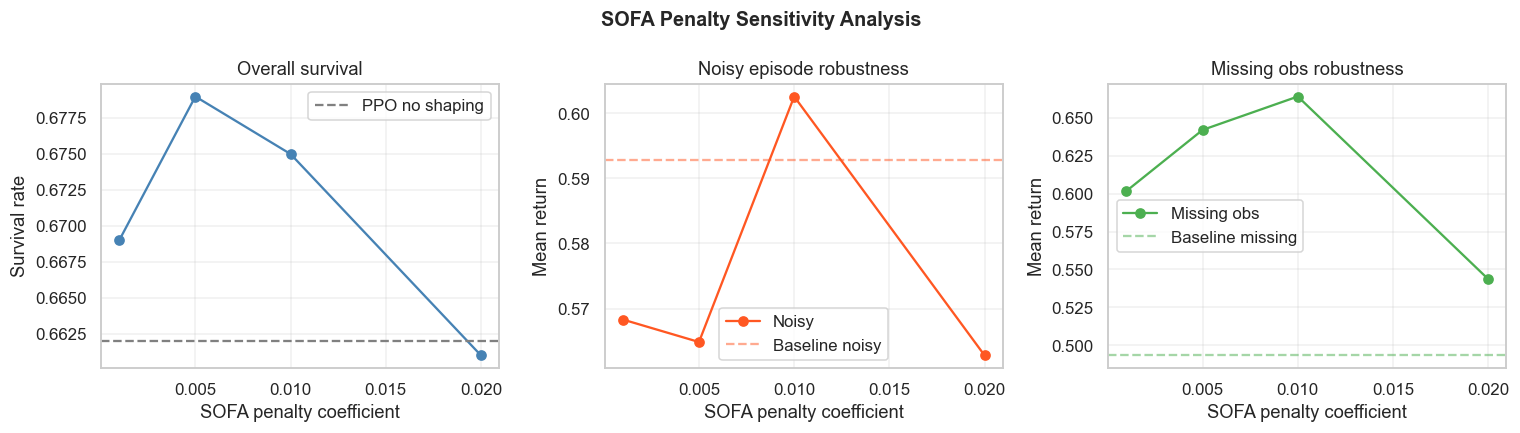

In [61]:
from stable_baselines3.common.env_util import make_vec_env

PENALTY_VALUES = [0.001, 0.005, 0.01, 0.02]
penalty_results = {}

for penalty in PENALTY_VALUES:
    print(f"Training PPO with SOFA penalty={penalty}...")

    def make_penalty_env(p=penalty):
        return SOFAShapingWrapper(make_clinical_env(), sofa_idx=SOFA_IDX, penalty=p)

    vec_env_p = make_vec_env(make_penalty_env, n_envs=4, seed=SEED)
    model_p = PPO("MlpPolicy", vec_env_p, learning_rate=3e-4, n_steps=1024,
                  batch_size=64, n_epochs=10, gamma=0.99, gae_lambda=0.95,
                  clip_range=0.2, ent_coef=0.03,
                  policy_kwargs=dict(net_arch=[dict(pi=[128,128], vf=[128,128])]),
                  verbose=0, seed=SEED)
    model_p.learn(total_timesteps=1_000_000, progress_bar=True)

    res = evaluate_sb3(model_p, n_episodes=1000, seed=SEED,
                       label=f"PPO SOFA penalty={penalty}")
    penalty_results[penalty] = res
    vec_env_p.close()

# Plot sensitivity
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle("SOFA Penalty Sensitivity Analysis", fontsize=13, fontweight="bold")

penalties     = list(penalty_results.keys())
survivals     = [penalty_results[p]["survival_rate"] for p in penalties]
noisy_means   = [penalty_results[p]["noisy_mean"]    for p in penalties]
missing_means = [penalty_results[p]["missing_mean"]  for p in penalties]

axes[0].plot(penalties, survivals, "o-", color="steelblue")
axes[0].axhline(r1["survival_rate"], color="gray", ls="--", label="PPO no shaping")
axes[0].set_xlabel("SOFA penalty coefficient")
axes[0].set_ylabel("Survival rate")
axes[0].set_title("Overall survival")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(penalties, noisy_means, "o-", color="#FF5722", label="Noisy")
axes[1].axhline(r1["noisy_mean"], color="#FF5722", ls="--", alpha=0.5, label="Baseline noisy")
axes[1].set_xlabel("SOFA penalty coefficient")
axes[1].set_ylabel("Mean return")
axes[1].set_title("Noisy episode robustness")
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(penalties, missing_means, "o-", color="#4CAF50", label="Missing obs")
axes[2].axhline(r1["missing_mean"], color="#4CAF50", ls="--", alpha=0.5, label="Baseline missing")
axes[2].set_xlabel("SOFA penalty coefficient")
axes[2].set_ylabel("Mean return")
axes[2].set_title("Missing obs robustness")
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("configB_sofa_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

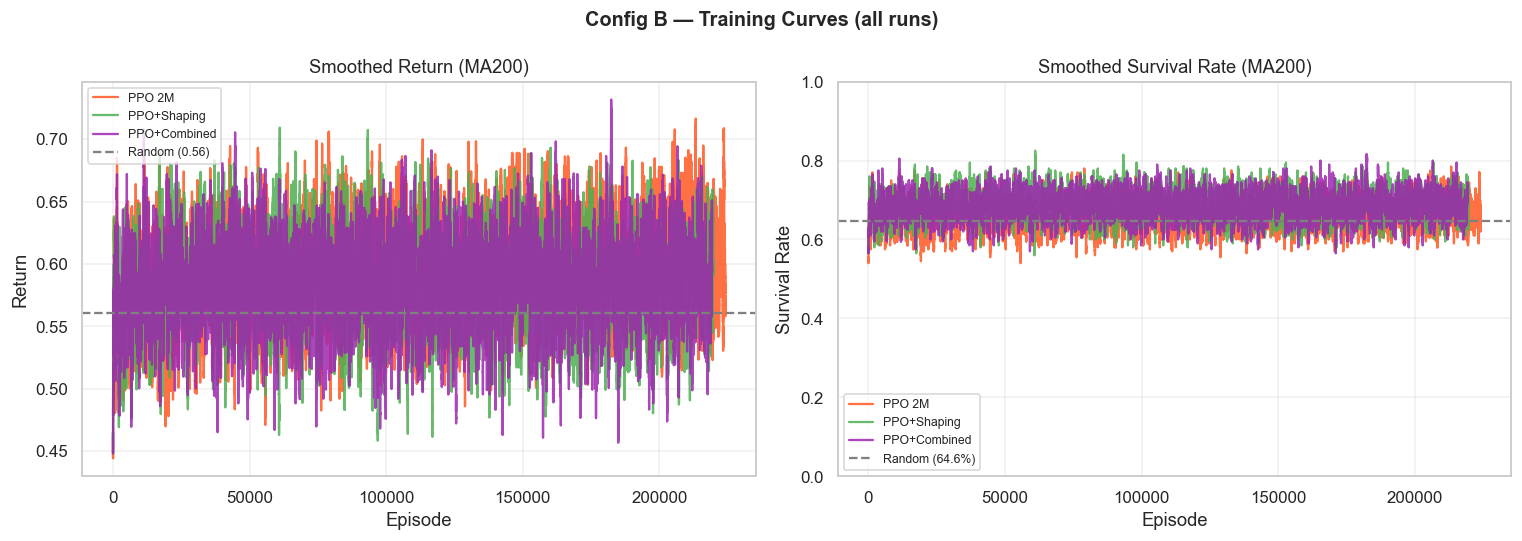

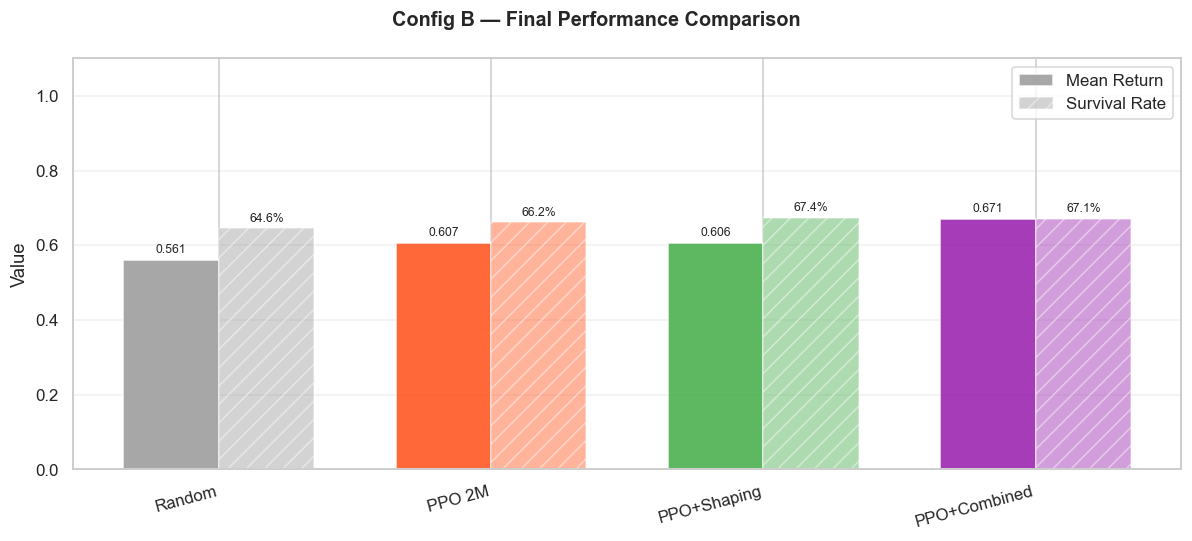

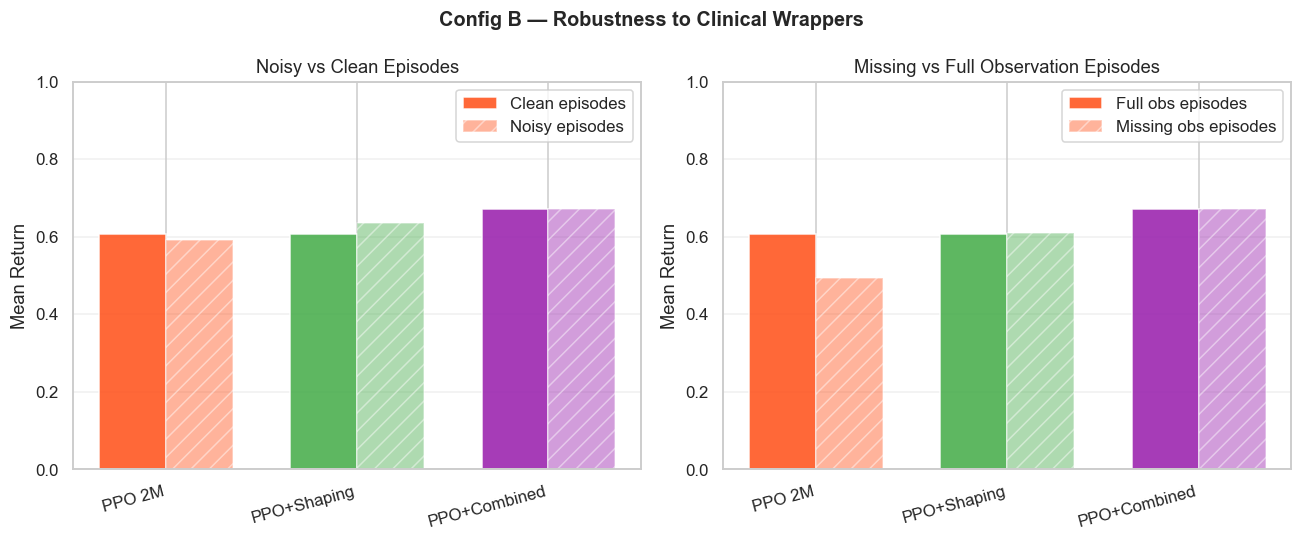

In [ ]:
# ── Data ─────────────────────────────────────────────────────────────────────
# Load saved returns 
ppo_shaped_returns  = np.load("ppo_shaped_returns.npy")
ppo_combined_returns= np.load("ppo_combined_returns.npy")
a2c_returns         = np.load("a2c_returns.npy")

RANDOM_SURVIVAL  = 0.646
RANDOM_BASELINE  = clinical_rand_mean

runs = {
    "PPO 2M":       {"returns": ppo_long_returns,     "color": "#FF5722", "survival": r1["survival_rate"], "mean": r1["mean_return"], "noisy": r1.get("noisy_mean"), "missing": r1.get("missing_mean")},
    "PPO+Shaping":  {"returns": ppo_shaped_returns,   "color": "#4CAF50", "survival": r2["survival_rate"], "mean": r2["mean_return"], "noisy": r2.get("noisy_mean"), "missing": r2.get("missing_mean")},
    "PPO+Combined": {"returns": ppo_combined_returns, "color": "#9C27B0", "survival": r4['survival_rate'],               "mean": r4['survival_rate'],            "noisy": r4['survival_rate'],                 "missing": r4['survival_rate']},
}

def smooth(x, w=200):
    return np.convolve(x, np.ones(w) / w, mode="valid")

# ── Figure 1: Training curves ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Config B — Training Curves (all runs)", fontsize=13, fontweight="bold")

for name, d in runs.items():
    axes[0].plot(smooth(d["returns"]), color=d["color"], label=name, alpha=0.85)
axes[0].axhline(RANDOM_BASELINE, color="gray", ls="--", label=f"Random ({RANDOM_BASELINE:.2f})")
axes[0].set_title("Smoothed Return (MA200)")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Return")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

for name, d in runs.items():
    surv = [1.0 if r > 0 else 0.0 for r in d["returns"]]
    axes[1].plot(smooth(surv, 200), color=d["color"], label=name, alpha=0.85)
axes[1].axhline(RANDOM_SURVIVAL, color="gray", ls="--", label=f"Random ({RANDOM_SURVIVAL:.1%})")
axes[1].set_title("Smoothed Survival Rate (MA200)")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Survival Rate")
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("configB_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Figure 2: Final performance bar chart ────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 5))
fig.suptitle("Config B — Final Performance Comparison", fontsize=13, fontweight="bold")

x = np.arange(len(labels))
w = 0.35
bars1 = ax.bar(x - w/2, means, w, color=colors, alpha=0.9,  label="Mean Return")
bars2 = ax.bar(x + w/2, survs, w, color=colors, alpha=0.45, label="Survival Rate", hatch="//")
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.1%}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=15, ha="right")
ax.set_ylim(0, 1.1)
ax.set_ylabel("Value")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("configB_final_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Figure 3: Robustness breakdown (noisy / missing) ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Config B — Robustness to Clinical Wrappers", fontsize=13, fontweight="bold")

rob_runs   = {k: v for k, v in runs.items() if v["noisy"] is not None}
rob_labels = list(rob_runs.keys())
rob_colors = [d["color"] for d in rob_runs.values()]

# Noisy vs clean
noisy_vals   = [d["noisy"]   for d in rob_runs.values()]
clean_vals   = [d["mean"]    for d in rob_runs.values()]

x = np.arange(len(rob_labels))
axes[0].bar(x - w/2, clean_vals, w, color=rob_colors, alpha=0.9,  label="Clean episodes")
axes[0].bar(x + w/2, noisy_vals, w, color=rob_colors, alpha=0.45, label="Noisy episodes", hatch="//")
axes[0].set_xticks(x); axes[0].set_xticklabels(rob_labels, rotation=15, ha="right")
axes[0].set_ylabel("Mean Return")
axes[0].set_title("Noisy vs Clean Episodes")
axes[0].set_ylim(0, 1)
axes[0].legend(); axes[0].grid(axis="y", alpha=0.3)

# Missing vs full obs
missing_vals = [d["missing"] for d in rob_runs.values()]
full_vals    = [d["mean"]    for d in rob_runs.values()]
axes[1].bar(x - w/2, full_vals,    w, color=rob_colors, alpha=0.9,  label="Full obs episodes")
axes[1].bar(x + w/2, missing_vals, w, color=rob_colors, alpha=0.45, label="Missing obs episodes", hatch="//")
axes[1].set_xticks(x); axes[1].set_xticklabels(rob_labels, rotation=15, ha="right")
axes[1].set_ylabel("Mean Return")
axes[1].set_title("Missing vs Full Observation Episodes")
axes[1].set_ylim(0, 1)
axes[1].legend(); axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("configB_robustness.png", dpi=150, bbox_inches="tight")
plt.show()

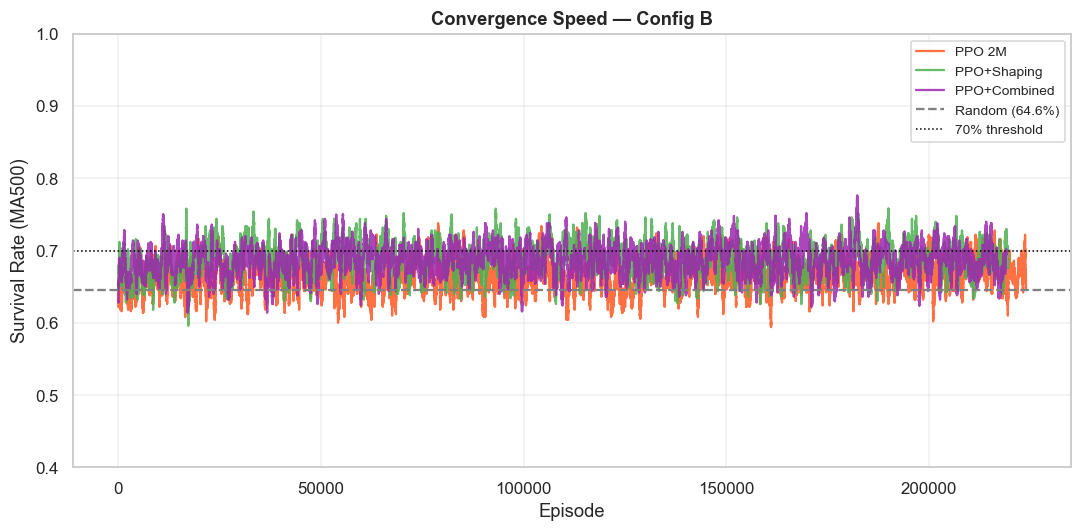

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

w = 500
for name, d in runs.items():
    if d["returns"] is None:
        continue
    surv = [1.0 if r > 0 else 0.0 for r in d["returns"]]
    smoothed = smooth(surv, w)
    ax.plot(smoothed, color=d["color"], label=name, alpha=0.85)

ax.axhline(RANDOM_SURVIVAL, color="gray", ls="--", label=f"Random ({RANDOM_SURVIVAL:.1%})")
ax.axhline(0.70, color="black", ls=":", lw=1, label="70% threshold")
ax.set_xlabel("Episode")
ax.set_ylabel("Survival Rate (MA500)")
ax.set_title("Convergence Speed — Config B", fontweight="bold")
ax.set_ylim(0.4, 1.0)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("configB_convergence.png", dpi=150, bbox_inches="tight")
plt.show()

make_sepsis_env | lam=0.02 → intensity penalty active

make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02

make_sepsis_env | lam=0.02 → intensity penalty active

make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02

make_sepsis_env | lam=0.02 → intensity penalty active

make_sepsis_env | sofa_bias=5.0 → mean start SOFA: 9.02

Action entropy per algorithm (exploration proxy):

PPO 2M        : entropy=2.857 (88.8% of max)

PPO+Shaping   : entropy=2.999 (93.2% of max)

PPO+Combined  : entropy=3.029 (94.1% of max)

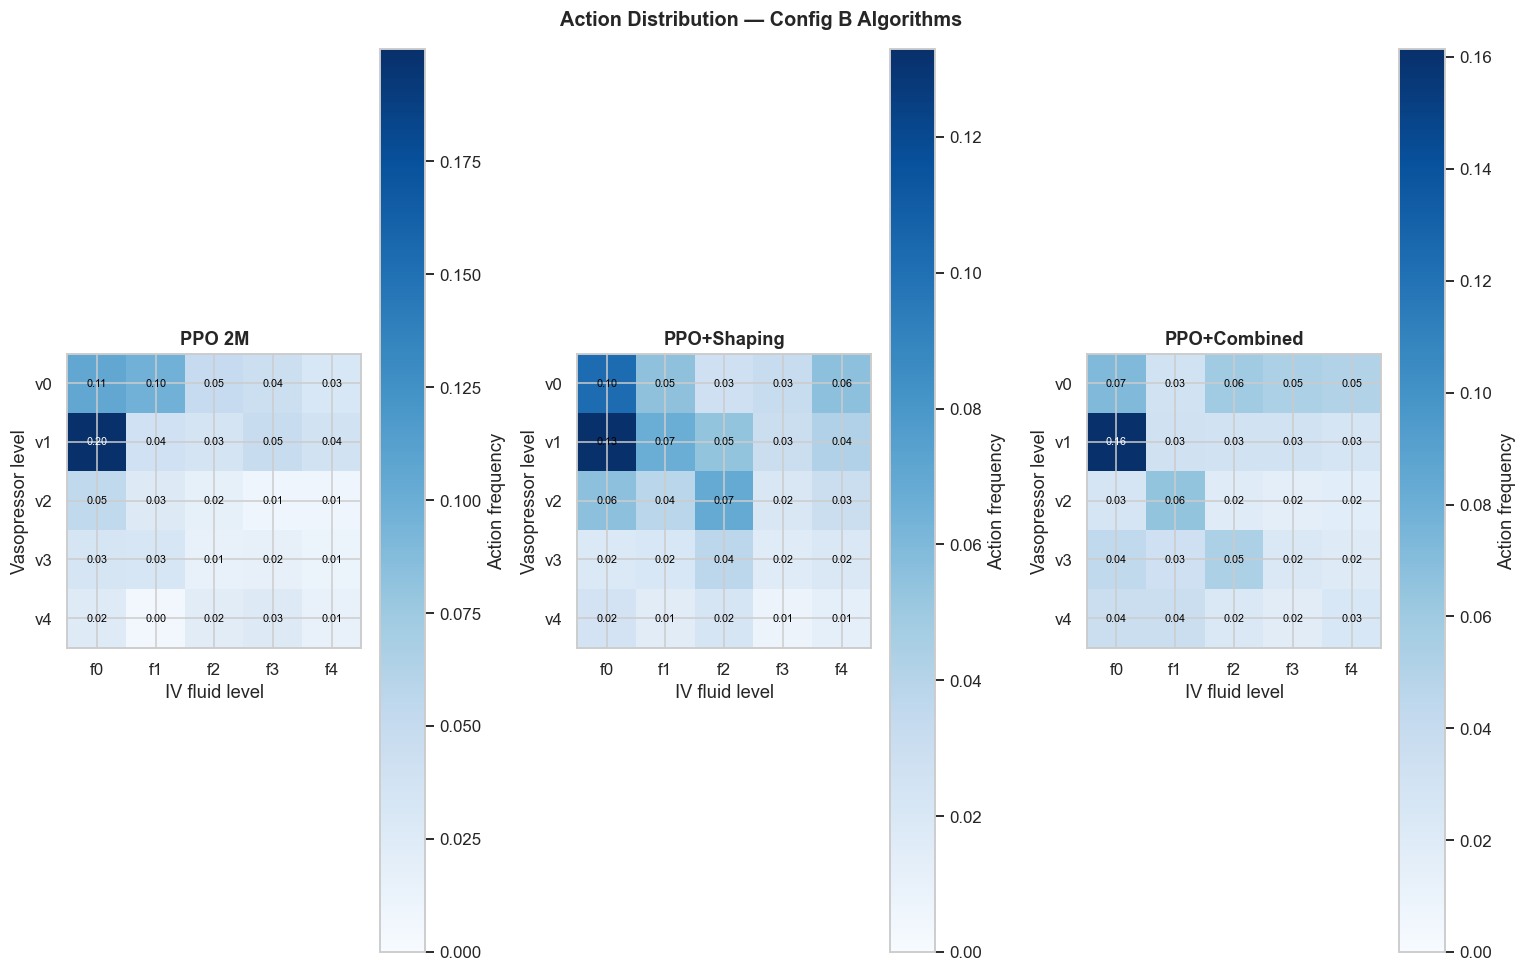

In [114]:
def get_action_distribution(model, n_episodes=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    env_check = make_clinical_env()
    counts = np.zeros(25)
    for _ in range(n_episodes):
        obs, _ = env_check.reset(seed=int(rng.integers(0, 100_000)))
        done = False
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            counts[int(action)] += 1
            obs, _, te, tr, _ = env_check.step(int(action))
            done = te or tr
    env_check.close()
    return counts / counts.sum()

action_dists = {
    "PPO 2M":      get_action_distribution(ppo_long),
    "PPO+Shaping": get_action_distribution(ppo_shaped),
    "PPO+Combined": get_action_distribution(ppo_combined),
}

# Entropy as exploration metric
print("Action entropy per algorithm (exploration proxy):")
for name, dist in action_dists.items():
    entropy = -np.sum(dist * np.log(dist + 1e-9))
    max_entropy = np.log(25)
    print(f"  {name:<14}: entropy={entropy:.3f} ({entropy/max_entropy*100:.1f}% of max)")

# Heatmap
fig, axes = plt.subplots(1, 3, figsize=(14, 9))
fig.suptitle("Action Distribution — Config B Algorithms", fontsize=13, fontweight="bold")

for ax, (name, dist) in zip(axes.flatten(), action_dists.items()):
    grid = dist.reshape(5, 5)
    im = ax.imshow(grid, cmap="Blues", vmin=0)
    ax.set_xticks(range(5)); ax.set_xticklabels([f"f{i}" for i in range(5)])
    ax.set_yticks(range(5)); ax.set_yticklabels([f"v{i}" for i in range(5)])
    ax.set_xlabel("IV fluid level")
    ax.set_ylabel("Vasopressor level")
    ax.set_title(name, fontweight="bold")
    plt.colorbar(im, ax=ax, label="Action frequency")
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{grid[i,j]:.2f}", ha="center", va="center",
                    fontsize=7, color="white" if grid[i,j] > 0.15 else "black")

plt.tight_layout()
plt.savefig("configB_action_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

In [117]:
print(f"PPO 2M     : survival={r1['survival_rate']*100:.1f}%, return={r1['mean_return']:.4f}, noisy={r1['noisy_mean']:.4f}, missing={r1['missing_mean']:.4f}")
print(f"PPO+Shaping: survival={r2['survival_rate']*100:.1f}%, return={r2['mean_return']:.4f}, noisy={r2['noisy_mean']:.4f}, missing={r2['missing_mean']:.4f}")
print(f"PPO+Combined: survival={r4['survival_rate']*100:.1f}%, return={r4['mean_return']:.4f}, noisy={r4['noisy_mean']:.4f}, missing={r4['missing_mean']:.4f}")

PPO 2M     : survival=66.2%, return=0.6068, noisy=0.5927, missing=0.4933

PPO+Shaping: survival=67.4%, return=0.6062, noisy=0.6344, missing=0.6091

PPO+Combined: survival=67.1%, return=0.6015, noisy=0.6069, missing=0.5993

In [118]:
for name, dist in action_dists.items():
    entropy = -np.sum(dist * np.log(dist + 1e-9))
    print(f"{name}: entropy={entropy:.3f} ({entropy/np.log(25)*100:.1f}% of max)")

PPO 2M: entropy=2.857 (88.8% of max)

PPO+Shaping: entropy=2.999 (93.2% of max)

PPO+Combined: entropy=3.029 (94.1% of max)

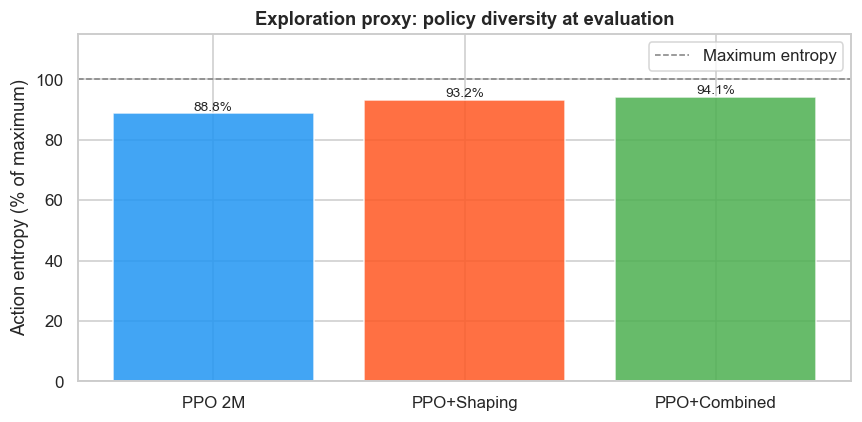

In [119]:
fig, ax = plt.subplots(figsize=(8, 4))
names = list(action_dists.keys())
entropies = [-np.sum(d * np.log(d + 1e-9)) / np.log(25) * 100 
             for d in action_dists.values()]
colors = ["#2196F3", "#FF5722", "#4CAF50", "#FF9800"]
ax.bar(names, entropies, color=colors, alpha=0.85)
ax.axhline(100, color="gray", ls="--", lw=1, label="Maximum entropy")
ax.set_ylabel("Action entropy (% of maximum)")
ax.set_title("Exploration proxy: policy diversity at evaluation", fontweight="bold")
ax.set_ylim(0, 115)
for i, v in enumerate(entropies):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig("configB_entropy.png", dpi=150, bbox_inches="tight")
plt.show()

In [120]:
threshold = 0.70
for name, d in runs.items():
    surv = [1.0 if r > 0 else 0.0 for r in d["returns"]]
    smoothed = smooth(surv, 200)
    crossing = next((i for i, v in enumerate(smoothed) if v >= threshold), None)
    if crossing:
        print(f"{name}: crossed {threshold:.0%} at episode {crossing}")
    else:
        print(f"{name}: never crossed {threshold:.0%}")

PPO 2M: crossed 70% at episode 313

PPO+Shaping: crossed 70% at episode 271

PPO+Combined: crossed 70% at episode 364